# Appendix — coherent vs directly predicted GGI

Compares the internally coherent GGI (derived as predicted-female / predicted-male) against the
separately modelled GGI, across five appendix analyses:

| | |
| --- | --- |
| **A** | Scatter, direct vs coherent raw, by continent, for 2015 / 2020 / 2025 |
| **B** | Distribution of the difference (coherent − direct) |
| **C** | Country trajectories under both definitions, for a rule-selected country set |
| **D** | Regional robustness under three definitions, with a rank table |
| **E** | Paper-ready appendix paragraph |

**All data is prepared by `src/14_coherent_ggi_comparison.py`** and read from `outputs/tables/`.
This notebook contains plotting only — no analysis is computed here, so every number in a figure is
traceable to a saved CSV.

Two things carried over from the main analysis: the sample excludes Yemen and the sanctioned
countries (D21), and the trend window ends 2025, the last complete year (D18).

In [1]:
import sys
from pathlib import Path

# put src/ on the path — this notebook lives in src/analysis_notebooks/
SRC = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'params.py').exists())
sys.path.insert(0, str(SRC))
import re
import warnings

import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import ggi_comparison
import params
import plotting as plot

NOTEBOOK = '05_coherent_ggi_comparison'

warnings.filterwarnings('ignore')

STYLE = params.STYLE          # saving is on by default (shared_style.STYLE['save'])
PALETTE = STYLE['colors']
# The ink, and the palette, come from one place — src/shared_style.py, applied by plotting.py
# (D52). Restating the hexes here is how two figures end up with two greys.
INK, MUTED, GRID = plot.INK, plot.MUTED, plot.GRID
FIGDIR = params.fig_dir(NOTEBOOK)
FIGDIR.mkdir(parents=True, exist_ok=True)


# ----------------------------------------------------------------------------------------------------
# build this notebook's own analysis
# ----------------------------------------------------------------------------------------------------
# The tables below are CREATED here by calling src/ggi_comparison.py, not read back from a previous
# run of this notebook. Only inputs from *earlier* stages are read from disk: the coherent-GGI
# country-year series (04) and the survey validation (02/03).
annual_all = ggi_comparison.load_country_year()
annual, dropped = ggi_comparison.common_sample(annual_all)

scatter, scatter_stats = ggi_comparison.build_scatter(annual)
differences, diff_summary = ggi_comparison.build_differences(annual)
selection = ggi_comparison.select_trend_countries(annual)
trends = ggi_comparison.build_trends(annual, selection)
regional, regional_table = ggi_comparison.build_regional(annual)
stability = ggi_comparison.rank_stability(regional_table)

print(f"common sample: {annual['gid_0'].nunique()} countries ({len(dropped)} dropped)")


def latest_gt(stem):
    """
    the survey-validation tables, produced by 02_model_performance.ipynb

    An earlier stage's result, so it is read rather than rebuilt — rebuilding it here would put
    two copies of the same analysis in the repo.
    """
    matches = sorted(f for f in params.table_dir('02_model_performance').glob(
        f'model_performance_{stem}_*.csv')
        if re.fullmatch(rf'model_performance_{stem}_\d{{8}}\.csv', f.name))
    if not matches:
        raise FileNotFoundError(f'no model_performance_{stem}_<date>.csv — run 02 first')
    return pd.read_csv(matches[-1])


gt             = latest_gt('groundtruth')
gt_stats       = latest_gt('groundtruth_stats')
gt_levels      = latest_gt('groundtruth_levels')
gt_level_stats = latest_gt('groundtruth_level_stats')
unseen         = latest_gt('unseen_surveys')

CONTINENTS = sorted(scatter['continent'].dropna().unique())
CONTINENT_COLOUR = dict(zip(CONTINENTS, PALETTE))
DEF_LABEL = {'coherent_parity': 'Coherent (parity-capped)',
             'coherent_raw': 'Coherent (raw)',
             'direct': 'Directly predicted'}

# Section F distinguishes two things only, so it takes the first two hues of the project's
# categorical order (params.plot_color_order — red and navy, the ramp's two ends, D53) and
# backs them with marker shape, so the split survives a greyscale print.
SAMPLE_COLOUR = {'held_out': PALETTE[1], 'in_training': PALETTE[0], 'all': PALETTE[0],
                 'all_excl_zero': PALETTE[2]}
SAMPLE_MARKER = {'held_out': '^', 'in_training': 'o', 'all': 'o', 'all_excl_zero': 's'}
SAMPLE_LABEL = {'held_out': 'Held out (not fitted)', 'in_training': 'In the fitted panel',
                'all': 'All surveys', 'all_excl_zero': 'Excluding zero-floor rows'}

# Rows where the predicted female level sits on the zero floor: the coherent GGI is 0/male = 0 by
# construction there (D19), so it reports the clip rather than a gap. params.delete_coherent_zero_ctrl
# decides whether the filtered sample is reported alongside; the mark below is always drawn.
ZERO_CTRL = params.delete_coherent_zero_ctrl
ZERO_RING = plot.FLAG

print(f"{scatter['gid_0'].nunique()} countries | continents: {', '.join(CONTINENTS)}")


def tidy(ax, title=None, xlabel=None, ylabel=None):
    """the project's axis treatment: recessive frame, muted labels, y-grid only"""
    if title:
        ax.set_title(title, fontsize=STYLE['label_fs'], color=INK, fontweight='bold', loc='left')
    if xlabel:
        ax.set_xlabel(xlabel, fontsize=STYLE['tick_fs'], color=MUTED)
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=STYLE['tick_fs'], color=MUTED)
    ax.tick_params(labelsize=STYLE['annot_fs'], colors=MUTED)
    ax.grid(axis='y', color=GRID, linewidth=0.5, alpha=0.6)
    ax.set_axisbelow(True)
    for s in ['top', 'right']:
        ax.spines[s].set_visible(False)
    for s in ['left', 'bottom']:
        ax.spines[s].set_color(GRID)
    return ax

common sample: 210 countries (1 dropped)
210 countries | continents: Africa, Asia, Europe, North America, Oceania, South America


## A. Direct vs coherent, by continent

x is the directly predicted GGI, y the **raw** (uncapped) coherent GGI. Axes deliberately extend
past 1 so values above parity are visible rather than truncated — that is where the two definitions
diverge most. The dashed line is y = x: points above it are countries where the coherent measure
reports a *smaller* gender gap than the direct model does.

,indicator,year,n,pearson_r,spearman_r,n_above_1_coherent_raw,max_coherent_raw,mean_abs_diff
0,internet,2015,210,0.9217,0.8454,29,1.3948,0.0801
1,internet,2020,210,0.9259,0.8727,39,1.1008,0.0461
2,internet,2025,210,0.9297,0.8576,26,1.0698,0.0327
3,mobile,2015,210,0.9841,0.8970,52,1.0743,0.0176
4,mobile,2020,210,0.9765,0.8656,88,1.1182,0.0195
5,mobile,2025,210,0.9605,0.8153,87,1.1240,0.0193


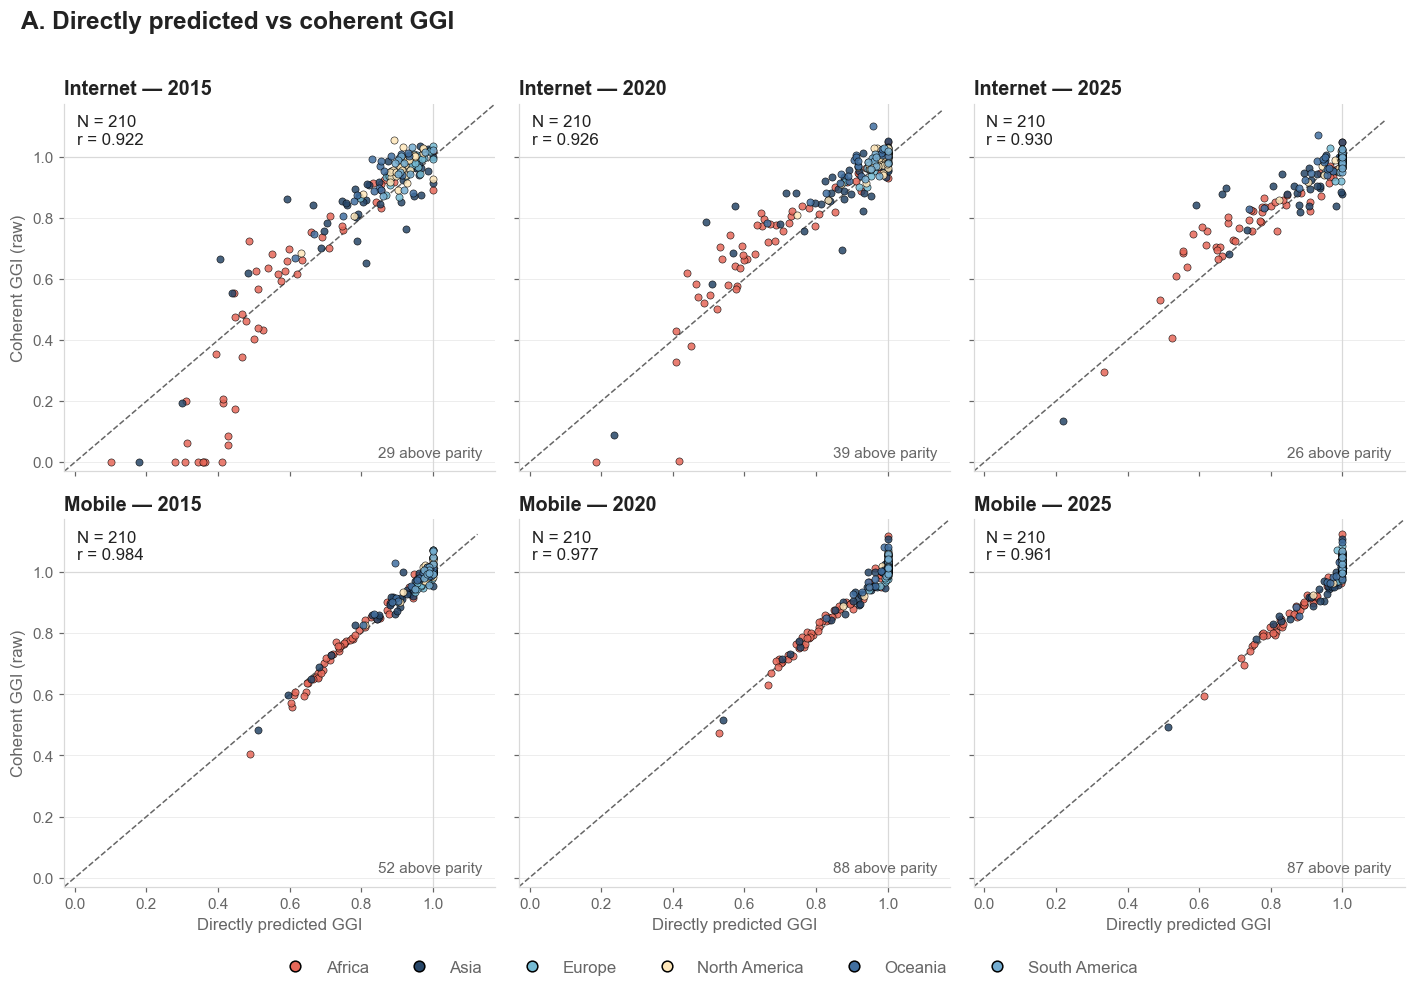

In [2]:
fig, axes = plt.subplots(2, 3, figsize=plot.figsize('tall'), sharex=True, sharey=True)

for row, indicator in enumerate(params.COHERENT_GGI['indicators']):
    for col, year in enumerate(params.COHERENT_GGI['focus_years']):
        ax = axes[row, col]
        block = scatter[(scatter['indicator'] == indicator) & (scatter['year'] == year)]
        st = scatter_stats[(scatter_stats['indicator'] == indicator)
                           & (scatter_stats['year'] == year)].iloc[0]

        lim = (-0.03, max(1.05, block[['direct', 'coherent_raw']].max().max() + 0.05))
        ax.plot(lim, lim, ls='--', color=MUTED, linewidth=1, zorder=1)
        ax.axhline(1.0, color=GRID, linewidth=0.8, zorder=1)
        ax.axvline(1.0, color=GRID, linewidth=0.8, zorder=1)

        for continent in CONTINENTS:
            pts = block[block['continent'] == continent]
            ax.scatter(pts['direct'], pts['coherent_raw'], s=22, alpha=0.85,
                       color=CONTINENT_COLOUR[continent], edgecolor=plot.EDGE,
                       linewidth=0.4, zorder=3)

        ax.text(0.03, 0.97, f"N = {int(st['n'])}\nr = {st['pearson_r']:.3f}",
                transform=ax.transAxes, va='top', ha='left',
                fontsize=STYLE['tick_fs'], color=INK)
        ax.text(0.97, 0.03, f"{int(st['n_above_1_coherent_raw'])} above parity",
                transform=ax.transAxes, va='bottom', ha='right',
                fontsize=STYLE['annot_fs'], color=MUTED)

        tidy(ax, title=f'{indicator.capitalize()} — {year}')
        ax.set_xlim(lim); ax.set_ylim(lim)
        if row == 1:
            ax.set_xlabel('Directly predicted GGI', fontsize=STYLE['tick_fs'], color=MUTED)
        if col == 0:
            ax.set_ylabel('Coherent GGI (raw)', fontsize=STYLE['tick_fs'], color=MUTED)

# one figure-level legend: inside a panel it collided with the 'above parity' annotation
handles = [plt.Line2D([], [], marker='o', linestyle='None', markersize=7,
                      markerfacecolor=CONTINENT_COLOUR[c], markeredgecolor=plot.EDGE, label=c)
           for c in CONTINENTS]
fig.legend(handles=handles, loc='lower center', ncol=len(CONTINENTS), frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.01))
fig.suptitle('A. Directly predicted vs coherent GGI', fontsize=STYLE['title_fs'],
             color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0.03, 1, 0.97])
plot.save_fig(fig, FIGDIR / 'A_scatter_direct_vs_coherent.png')
scatter_stats.round(4)

## B. Distribution of the difference

`coherent (parity-capped) − direct`, pooled over 2015–2025. The left panel is the full distribution;
the right splits by continent. The dashed line marks zero — perfect agreement between definitions.

,indicator,continent,n,mean,median,sd,q05,q95,pct_positive
0,internet,Africa,572,0.0156,0.0332,0.1107,-0.2425,0.1541,68.1818
1,internet,Asia,506,0.0218,0.0097,0.0849,-0.1159,0.1782,54.1502
2,internet,Europe,495,0.0064,0.0000,0.0223,-0.0270,0.0495,41.2121
3,internet,North America,385,0.0147,0.0102,0.0297,-0.0284,0.0639,58.4416
4,internet,Oceania,220,0.0526,0.0507,0.0467,-0.0081,0.1192,85.9091
5,internet,South America,132,0.0094,0.0008,0.0315,-0.0357,0.0684,50.7576
6,mobile,Africa,572,0.0033,0.0040,0.0177,-0.0306,0.0272,59.0909
7,mobile,Asia,506,0.0017,0.0000,0.0181,-0.0279,0.0308,37.9447
8,mobile,Europe,495,-0.0023,0.0000,0.0067,-0.0183,0.0000,4.6465
9,mobile,North America,385,0.0013,0.0000,0.0057,-0.0051,0.0152,17.1429


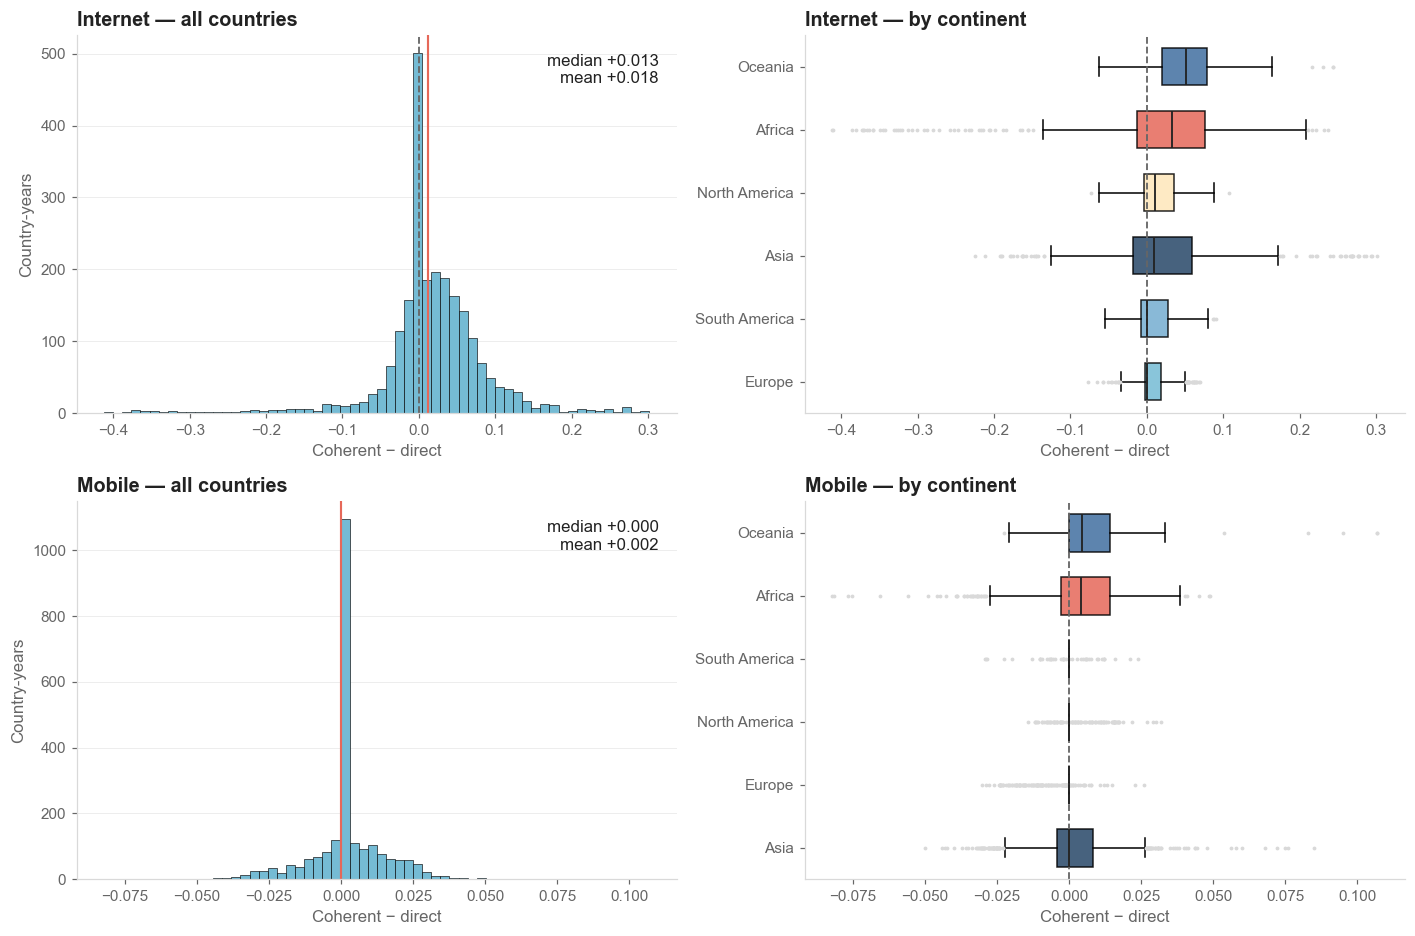

In [28]:
fig, axes = plt.subplots(2, 2, figsize=plot.figsize('tall'))

for row, indicator in enumerate(params.COHERENT_GGI['indicators']):
    block = differences[differences['indicator'] == indicator]

    ax = axes[row, 0]
    ax.hist(block['diff_parity'].dropna(), bins=60, color=PALETTE[2],
            edgecolor=plot.EDGE, linewidth=0.4)
    ax.axvline(0, ls='--', color=MUTED, linewidth=1.2)
    med = block['diff_parity'].median()
    ax.axvline(med, ls='-', color=PALETTE[0], linewidth=1.4)
    ax.text(0.97, 0.95, f'median {med:+.3f}\nmean {block["diff_parity"].mean():+.3f}',
            transform=ax.transAxes, ha='right', va='top',
            fontsize=STYLE['tick_fs'], color=INK)
    tidy(ax, title=f'{indicator.capitalize()} — all countries',
         xlabel='Coherent − direct', ylabel='Country-years')

    ax = axes[row, 1]
    order = (block.groupby('continent')['diff_parity'].median().sort_values().index.tolist())
    data = [block.loc[block['continent'] == c, 'diff_parity'].dropna() for c in order]
    bp = ax.boxplot(data, vert=False, patch_artist=True, widths=0.6,
                    medianprops=dict(color=INK, linewidth=1.2),
                    flierprops=dict(marker='.', markersize=3, markerfacecolor=GRID,
                                    markeredgecolor=GRID))
    for patch, continent in zip(bp['boxes'], order):
        patch.set_facecolor(CONTINENT_COLOUR[continent])
        patch.set_alpha(0.85)
        patch.set_edgecolor(plot.EDGE)
    ax.axvline(0, ls='--', color=MUTED, linewidth=1.2)
    ax.set_yticks(range(1, len(order) + 1))
    ax.set_yticklabels(order)
    tidy(ax, title=f'{indicator.capitalize()} — by continent', xlabel='Coherent − direct')
    ax.grid(axis='y', visible=False)

#fig.suptitle('B. Difference between definitions (coherent − direct)',
#             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=[0, 0, 1, 0.96])
plot.save_fig(fig, FIGDIR / 'B_difference_distributions.png')
diff_summary.round(4)

## C. Choosing a discrepancy threshold

The coherent and directly predicted GGIs disagree far more for internet than for mobile, by about
an order of magnitude. The cell below prints the exact figures rather than repeating them here,
because there are two medians in play and they are easy to confuse:

- **Section B reports the SIGNED median**, +0.013 for internet — the typical *direction* of the
  difference, coherent running slightly above direct. Positives and negatives cancel in it.
- **A threshold acts on the ABSOLUTE difference**, whose median is about +0.029 for internet.
  That is the typical *size* of a disagreement, and it is roughly twice the signed figure precisely
  because the cancelling stops.

Both are correct and they are not the same quantity. Everything in this section uses the absolute
one.

Mobile's two constructions almost always agree; internet's often do not. Where they disagree
sharply, at least one of them is wrong about that country-year, and nothing in either series says
which — so those points carry a construction disagreement rather than a measured gender gap.

This section trials **thresholds on \|coherent − direct\|** for excluding such points. Two
strategies:

1. **Absolute** — drop country-years above a fixed cut, swept 0.05 to 0.10 in steps of 0.01.
2. **Within-continent IQR** — a Tukey rule applied to the discrepancy *within each continent*:
   drop points above `Q3 + k·IQR` of their own continent's distribution. Swept over k.

> **Reading `IRQ` as `IQR`.** The brief said "within continent IRQ"; IQR (interquartile range) is
> the statistic that fits "within continent", so that is what is implemented. If a different rule
> was meant, this is the one line to change.

**The criterion is the disagreement itself.** Both GGIs are parity-capped, so
`|coherent − direct|` is a like-for-like measure of how far the two constructions of the same
quantity diverge for a country-year. A threshold picks the point beyond which that divergence is
large enough that the country-year should not be carried into downstream analysis. What each cut
costs — country-years lost, countries lost, which ones — is the primary output below.

Agreement with the survey ground truth is reported **as a secondary check only**. It is not the
criterion: only 88 of 2,320 country-years have a survey at all, so it can corroborate a choice but
cannot make it.

**Nothing downstream is filtered yet.** Sections D onward and `06_coherent_ggi_decomposition` still
run on the full series; they get rewired once a strategy is chosen.

In [4]:
# The discrepancy every strategy thresholds on: |coherent - direct|, BOTH parity-capped.
# Checked rather than assumed — if one side were uncapped, a country whose direct GGI sat above
# parity would show a discrepancy that is purely a capping artefact, not a disagreement between
# the two constructions.
CAP = params.COHERENT_GGI['parity_cap']
disc = annual_all.copy()
for ind in params.COHERENT_GGI['indicators']:
    direct, coherent = disc[f'{ind}_ggi_direct'], disc[f'{ind}_ggi_coherent_parity']
    assert direct.max() <= CAP + 1e-9, f'{ind}_ggi_direct is not capped at {CAP}'
    assert coherent.max() <= CAP + 1e-9, f'{ind}_ggi_coherent_parity is not capped at {CAP}'
    disc[f'{ind}_disc'] = (coherent - direct).abs()
print(f'both definitions capped at {CAP}: verified — '
      f'0 values above the cap on either side, so no discrepancy here is a capping artefact')

# the premise, computed rather than quoted, on the frame this section actually uses
print(f'{"":10s} {"signed med":>11s} {"|abs| med":>10s} {">0.05":>7s} {">0.10":>7s}   n')
for ind in params.COHERENT_GGI['indicators']:
    signed = (disc[f'{ind}_ggi_coherent_parity'] - disc[f'{ind}_ggi_direct']).dropna()
    a = disc[f'{ind}_disc'].dropna()
    print(f'{ind:10s} {signed.median():+11.4f} {a.median():10.4f} '
          f'{100 * (a > 0.05).mean():6.1f}% {100 * (a > 0.10).mean():6.1f}%   {len(a)}')
print()

ABS_CUTS = np.round(np.arange(0.05, 0.1001, 0.01), 2)   # strategy 1
THRESHOLD = params.COHERENT_GGI['discrepancy_threshold']  # the one adopted, D43
IQR_KS = [0.5, 1.0, 1.5, 2.0, 3.0]                      # strategy 2, Tukey multiplier


def keep_absolute(frame, indicator, cut):
    """True where the two constructions agree to within `cut`"""
    return frame[f'{indicator}_disc'] <= cut


def keep_continent_iqr(frame, indicator, k):
    """
    True where the discrepancy is within its own continent's Tukey fence

    The fence is one-sided: only large disagreements are a problem, a small one is not an outlier
    worth dropping. Continents with too few points to form a quartile keep everything.
    """
    col = f'{indicator}_disc'
    keep = pd.Series(True, index=frame.index)
    for continent, block in frame.groupby('continent'):
        d = block[col].dropna()
        if len(d) < 8:
            continue
        q1, q3 = d.quantile(0.25), d.quantile(0.75)
        keep.loc[block.index] = block[col] <= q3 + k * (q3 - q1)
    return keep


def survey_agreement(kept_keys, indicator):
    """
    coherent-vs-survey MAE on the country-years that survive the filter

    `gt` holds the survey validation (from 02_model_performance). Filtering the series should, if
    the threshold is doing anything useful, leave a subset that agrees better with the surveys.
    """
    block = gt[(gt['indicator'] == indicator) & (gt['definition'] == 'coherent_parity')]
    inside = block[block.set_index(['gid_0', 'year']).index.isin(kept_keys)]
    direct = gt[(gt['indicator'] == indicator) & (gt['definition'] == 'direct')]
    direct_in = direct[direct.set_index(['gid_0', 'year']).index.isin(kept_keys)]
    return (len(inside),
            (inside['predicted'] - inside['observed']).abs().mean(),
            (direct_in['predicted'] - direct_in['observed']).abs().mean())


rows = []
for indicator in params.COHERENT_GGI['indicators']:
    block = disc.dropna(subset=[f'{indicator}_disc'])
    total, n_countries = len(block), block['gid_0'].nunique()

    trials = ([('absolute', c, keep_absolute(block, indicator, c)) for c in ABS_CUTS]
              + [('continent_iqr', k, keep_continent_iqr(block, indicator, k)) for k in IQR_KS])

    for strategy, level, keep in trials:
        kept = block[keep]
        keys = set(zip(kept['gid_0'], kept['year']))
        n_surv, mae_coh, mae_dir = survey_agreement(keys, indicator)
        rows.append({
            'indicator': indicator, 'strategy': strategy, 'level': level,
            'kept': int(keep.sum()), 'kept_pct': 100 * keep.mean(),
            'countries_kept': kept['gid_0'].nunique(),
            'countries_lost': n_countries - kept['gid_0'].nunique(),
            'countries_lost_entirely': n_countries - kept['gid_0'].nunique(),
            'max_disc_kept': kept[f'{indicator}_disc'].max(),
            'n_surveys': n_surv, 'survey_mae_coherent': mae_coh, 'survey_mae_direct': mae_dir,
        })

    # the unfiltered baseline, so every row above has something to be compared against
    keys_all = set(zip(block['gid_0'], block['year']))
    n_surv, mae_coh, mae_dir = survey_agreement(keys_all, indicator)
    rows.append({'indicator': indicator, 'strategy': 'none', 'level': np.nan,
                 'kept': total, 'kept_pct': 100.0, 'countries_kept': n_countries,
                 'countries_lost': 0, 'countries_lost_entirely': 0,
                 'max_disc_kept': block[f'{indicator}_disc'].max(),
                 'n_surveys': n_surv, 'survey_mae_coherent': mae_coh,
                 'survey_mae_direct': mae_dir})

trials = pd.DataFrame(rows)
trials['mae_gain'] = (trials['survey_mae_direct'] - trials['survey_mae_coherent'])
print(f'{len(trials)} trials over {disc["gid_0"].nunique()} countries')
trials.round(4)

both definitions capped at 1.0: verified — 0 values above the cap on either side, so no discrepancy here is a capping artefact
            signed med  |abs| med   >0.05   >0.10   n
internet       +0.0123     0.0291   32.7%   12.5%   2320
mobile         +0.0000     0.0023    1.0%    0.1%   2321

24 trials over 211 countries


,indicator,strategy,level,kept,kept_pct,countries_kept,countries_lost,countries_lost_entirely,max_disc_kept,n_surveys,survey_mae_coherent,survey_mae_direct,mae_gain
0,internet,absolute,0.05,1562,67.3276,192,19,19,0.0500,39,0.0915,0.0981,0.0066
1,internet,absolute,0.06,1722,74.2241,199,12,12,0.0600,51,0.0966,0.0970,0.0004
2,internet,absolute,0.07,1836,79.1379,201,10,10,0.0699,59,0.0970,0.0976,0.0006
3,internet,absolute,0.08,1921,82.8017,202,9,9,0.0797,65,0.0951,0.0940,-0.0011
4,internet,absolute,0.09,1989,85.7328,204,7,7,0.0900,67,0.0953,0.0927,-0.0026
5,internet,absolute,0.10,2031,87.5431,206,5,5,0.1000,69,0.0993,0.0941,-0.0052
6,internet,continent_iqr,0.50,2016,86.8966,208,3,3,0.1495,79,0.1062,0.0972,-0.0090
7,internet,continent_iqr,1.00,2164,93.2759,209,2,2,0.1915,84,0.1073,0.0958,-0.0115
8,internet,continent_iqr,1.50,2235,96.3362,209,2,2,0.2333,85,0.1090,0.0950,-0.0140
9,internet,continent_iqr,2.00,2263,97.5431,209,2,2,0.2719,85,0.1090,0.0950,-0.0140


### What each threshold costs and buys

Left: how much of the series survives. Right: how well the surviving coherent GGIs agree with the
survey ground truth, against the unfiltered baseline. The dashed line is the baseline; a threshold
is only worth applying if it moves the right-hand panel down while the left-hand panel stays high.

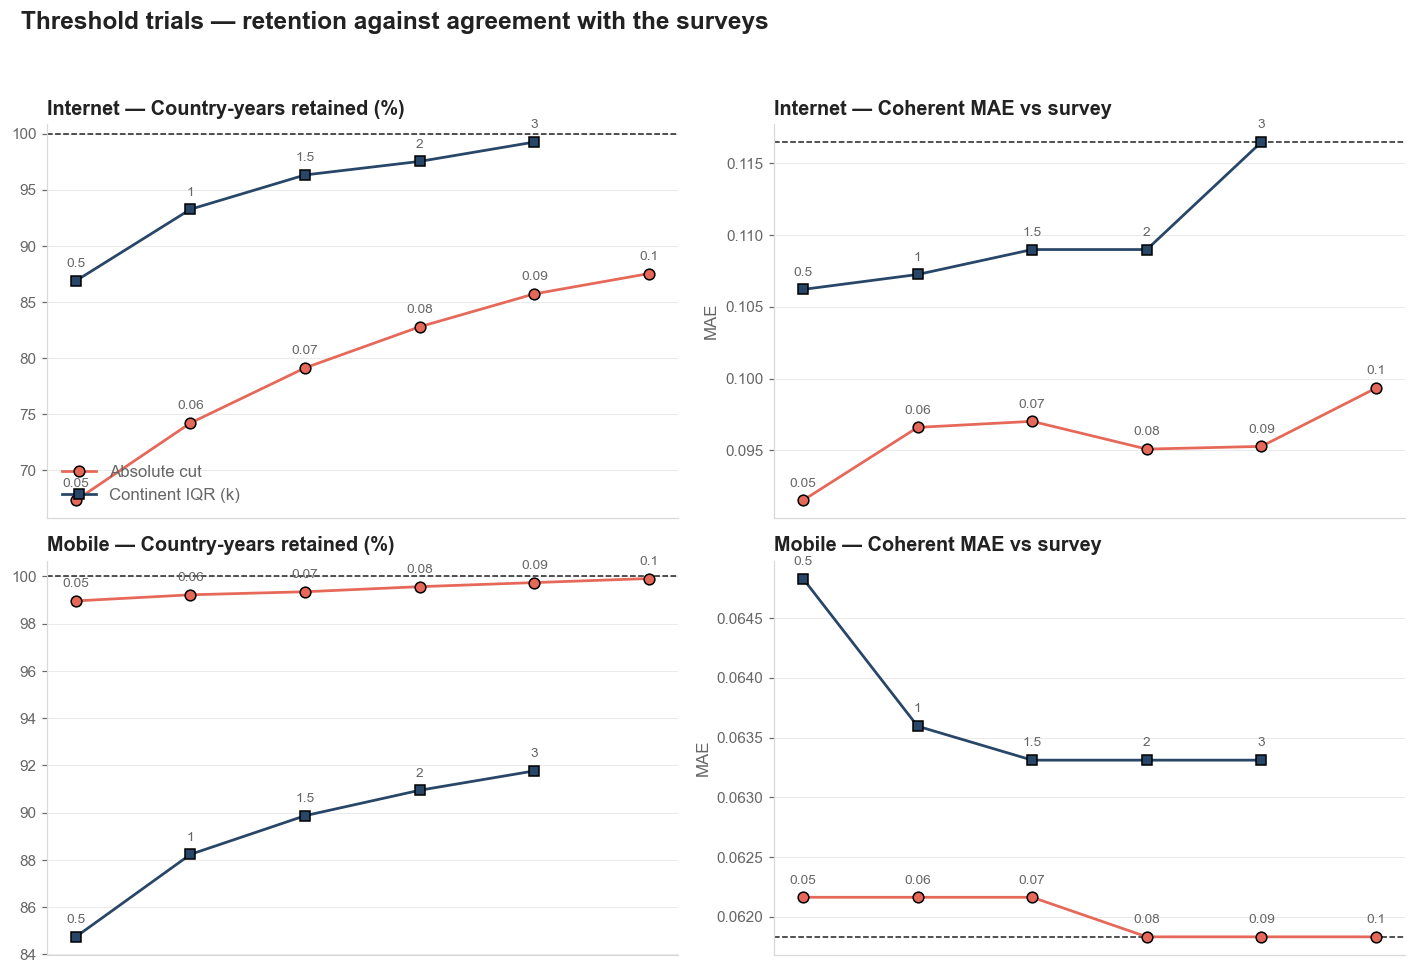

In [5]:
fig, axes = plt.subplots(2, 2, figsize=plot.figsize('tall'))

for row, indicator in enumerate(params.COHERENT_GGI['indicators']):
    block = trials[trials['indicator'] == indicator]
    base = block[block['strategy'] == 'none'].iloc[0]

    for col, (metric, label, better_low) in enumerate(
            [('kept_pct', 'Country-years retained (%)', False),
             ('survey_mae_coherent', 'Coherent MAE vs survey', True)]):
        ax = axes[row, col]
        for k, (strategy, marker) in enumerate([('absolute', 'o'), ('continent_iqr', 's')]):
            sub = block[block['strategy'] == strategy].sort_values('level')
            ax.plot(range(len(sub)), sub[metric], color=PALETTE[k], linewidth=1.8,
                    marker=marker, markersize=7, markeredgecolor=plot.EDGE, zorder=3,
                    label={'absolute': 'Absolute cut', 'continent_iqr': 'Continent IQR (k)'}[strategy])
            for x, (_, r) in enumerate(sub.iterrows()):
                ax.annotate(f"{r['level']:g}", (x, r[metric]), textcoords='offset points',
                            xytext=(0, 9), ha='center', fontsize=STYLE['small_fs'],
                            color=MUTED)
        ax.axhline(base[metric], color=INK, linewidth=1, linestyle='--', zorder=2)
        ax.set_xticks([])
        tidy(ax, title=f'{indicator.capitalize()} — {label}')
        ax.grid(axis='y', color=GRID, linewidth=0.6)
        ax.set_axisbelow(True)
        if col == 1:
            ax.set_ylabel('MAE', fontsize=STYLE['tick_fs'], color=MUTED)

axes[0, 0].legend(frameon=False, fontsize=STYLE['tick_fs'], labelcolor=MUTED, loc='lower left')
fig.suptitle('Threshold trials — retention against agreement with the surveys',
             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=(0, 0, 1, 0.95))
if STYLE['save']:
    plot.save_fig(fig, FIGDIR / 'C_threshold_trials.png')
plt.show()

### Where the discrepancy actually sits

A threshold is only sensible if the points it removes are a tail rather than a slice through the
middle of the distribution. Internet and mobile are drawn on the same axis so the difference in
scale is visible rather than hidden by separate limits.

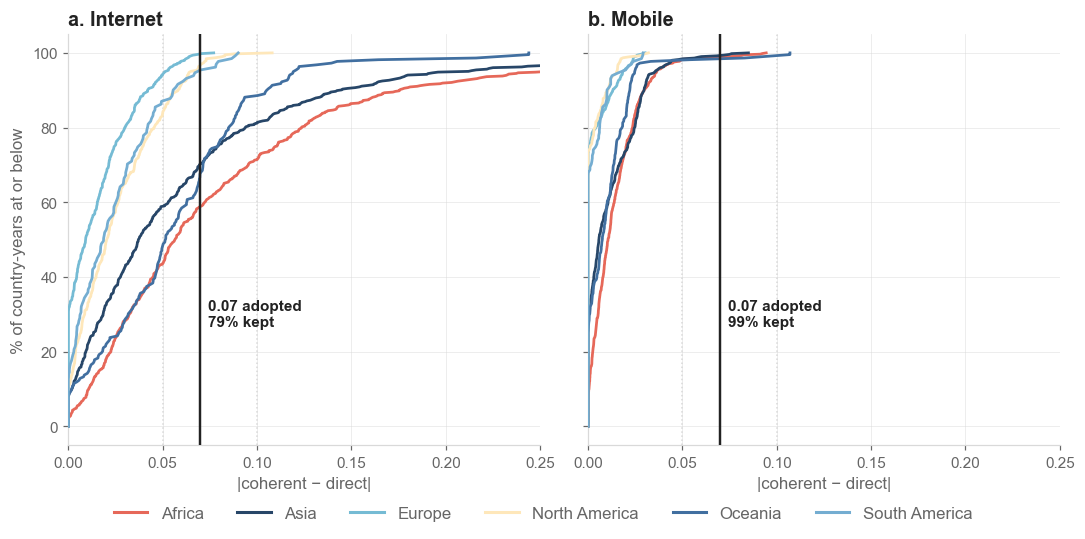

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(10,5), sharey=True)

# the two cuts worth reading off this figure, and the one adopted (D43)
MARKED = { THRESHOLD: 'adopted'} # 0.06: 'considered',

for ax, indicator in zip(axes, params.COHERENT_GGI['indicators']):
    block = disc.dropna(subset=[f'{indicator}_disc'])
    for k, continent in enumerate(CONTINENTS):
        d = block.loc[block['continent'] == continent, f'{indicator}_disc'].sort_values()
        if d.empty:
            continue
        ax.plot(d.values, np.linspace(0, 100, len(d)), color=CONTINENT_COLOUR[continent],
                linewidth=1.8, zorder=3, label=continent)

    # the sweep bounds, recessive: they frame the range tried rather than mark a choice. Left
    # unlabelled — the x ticks already read 0.05 and 0.10, and a second label there collides with
    # the annotation on the 0.06 line.
    for cut in ABS_CUTS[[0, -1]]:
        ax.axvline(cut, color=GRID, linewidth=1, linestyle=':', zorder=1)

    # 0.06 and 0.07 carry the decision, so they are drawn to be read: solid for the adopted cut,
    # dashed for the alternative, each labelled with what it retains on this indicator
    for cut, role in MARKED.items():
        kept = 100 * (block[f'{indicator}_disc'] <= cut).mean()
        adopted = role == 'adopted'
        ax.axvline(cut, color=INK if adopted else MUTED, linewidth=1.6 if adopted else 1.1,
                   linestyle='-' if adopted else (0, (5, 3)), zorder=4)
        ax.annotate(f'{cut:g} {role}\n{kept:.0f}% kept', (cut, 30 if adopted else 12),
                    xytext=(5, 0), textcoords='offset points', va='center', ha='left',
                    fontsize=STYLE['annot_fs'], color=INK if adopted else MUTED,
                    fontweight='bold' if adopted else 'normal')

    ax.set_xlim(0, 0.25)
    tidy(ax, title=f'{"a" if indicator == "internet" else "b"}. {indicator.capitalize()}', xlabel='|coherent − direct|')
    ax.grid(color=GRID, linewidth=0.5, alpha=0.6)
    ax.set_axisbelow(True)

axes[0].set_ylabel('% of country-years at or below', fontsize=STYLE['tick_fs'], color=MUTED)
handles = [plt.Line2D([], [], color=CONTINENT_COLOUR[c], linewidth=2, label=c) for c in CONTINENTS]
fig.legend(handles=handles, loc='lower center', ncol=len(CONTINENTS), frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.05))
#fig.suptitle('Discrepancy distribution by continent — the same axis for both indicators',
#             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=(0, 0, 1, 0.94))
if STYLE['save']:
    plot.save_fig(fig, FIGDIR / 'C_discrepancy_ecdf.png')
plt.show()


### The trials, side by side

`mae_gain` is `direct − coherent` on the retained surveys: **positive means the coherent GGI is
closer to the survey than the direct prediction is**, on that subset. Negative means the direct
prediction still wins, which is the situation across the board today (D33).

In [7]:
(trials[['indicator', 'strategy', 'level', 'kept', 'kept_pct', 'countries_kept',
         'max_disc_kept', 'n_surveys', 'survey_mae_coherent', 'survey_mae_direct', 'mae_gain']]
 .sort_values(['indicator', 'strategy', 'level'])
 .round(4).reset_index(drop=True))

,indicator,strategy,level,kept,kept_pct,countries_kept,max_disc_kept,n_surveys,survey_mae_coherent,survey_mae_direct,mae_gain
0,internet,absolute,0.05,1562,67.3276,192,0.0500,39,0.0915,0.0981,0.0066
1,internet,absolute,0.06,1722,74.2241,199,0.0600,51,0.0966,0.0970,0.0004
2,internet,absolute,0.07,1836,79.1379,201,0.0699,59,0.0970,0.0976,0.0006
3,internet,absolute,0.08,1921,82.8017,202,0.0797,65,0.0951,0.0940,-0.0011
4,internet,absolute,0.09,1989,85.7328,204,0.0900,67,0.0953,0.0927,-0.0026
5,internet,absolute,0.10,2031,87.5431,206,0.1000,69,0.0993,0.0941,-0.0052
6,internet,continent_iqr,0.50,2016,86.8966,208,0.1495,79,0.1062,0.0972,-0.0090
7,internet,continent_iqr,1.00,2164,93.2759,209,0.1915,84,0.1073,0.0958,-0.0115
8,internet,continent_iqr,1.50,2235,96.3362,209,0.2333,85,0.1090,0.0950,-0.0140
9,internet,continent_iqr,2.00,2263,97.5431,209,0.2719,85,0.1090,0.0950,-0.0140


### Why the within-continent IQR rule is the wrong instrument here

An IQR fence is **relative to each continent's own spread**, and the continents differ enormously in
spread. That makes the fence loosest exactly where the disagreement is worst:

| continent | n | Q3 | IQR | fence (k=1.5) | dropped |
| --- | --- | --- | --- | --- | --- |
| **Africa** | 582 | 0.110 | 0.084 | **0.237** | 33 |
| **Asia** | 506 | 0.079 | 0.066 | **0.178** | 32 |
| Oceania | 220 | 0.079 | 0.052 | 0.158 | 5 |
| North America | 385 | 0.040 | 0.033 | 0.089 | 1 |
| South America | 132 | 0.037 | 0.033 | 0.086 | 3 |
| **Europe** | 495 | 0.024 | 0.024 | **0.061** | 11 |

Africa's fence sits at **0.237** — nearly five times the 0.05 absolute cut — because its
discrepancies are widely spread. Europe's sits at 0.061. So the rule tolerates a 0.20 disagreement
in an African country-year while excluding a 0.07 one in a European country-year, which is the
opposite of a quality bar. It normalises away the very signal the threshold exists to act on.

That is a structural objection, not an empirical one: it holds at every `k`, and it is why the IQR
strategy keeps 93–99% of internet country-years while leaving the worst disagreements in.

**The same relativity makes it over-aggressive on mobile.** Mobile's discrepancies are tight, so the
fence is tight, and the rule drops **8–15%** of the series — far more than the absolute cut's 0.1–1%
— even though mobile has almost no genuine disagreement to remove.

An absolute cut is a fixed quality bar and does not have either property.

### What each cut removes

| indicator | strategy | kept | country-years lost | countries lost entirely |
| --- | --- | --- | --- | --- |
| internet | absolute 0.05 | 67.3% | 758 | **19** |
| internet | absolute 0.06 | 74.2% | 598 | 12 |
| internet | absolute 0.07 | 79.1% | 484 | 10 |
| internet | absolute 0.10 | 87.5% | 289 | 5 |
| internet | IQR k=1.5 | 96.3% | 85 | 2 |
| mobile | absolute 0.05 | 99.0% | 24 | 0 |
| mobile | IQR k=1.5 | 89.9% | 235 | 4 |

**Losing 19 countries entirely at 0.05 is the real cost of that cut**, and it is a bigger objection
than the accuracy numbers. Those countries drop out of every downstream regional aggregate, which
changes the composition of the regions rather than just their precision. 0.06 loses 12, 0.07 loses
10, 0.10 loses 5.


In [8]:
# the fences the IQR rule actually applies, per continent — the table above, computed
rows = []
for indicator in params.COHERENT_GGI['indicators']:
    block = disc.dropna(subset=[f'{indicator}_disc'])
    for continent, grp in block.groupby('continent'):
        d = grp[f'{indicator}_disc']
        if len(d) < 8:
            continue
        q1, q3 = d.quantile(0.25), d.quantile(0.75)
        for k in IQR_KS:
            fence = q3 + k * (q3 - q1)
            rows.append({'indicator': indicator, 'continent': continent, 'n': len(d),
                         'k': k, 'q3': q3, 'iqr': q3 - q1, 'fence': fence,
                         'dropped': int((d > fence).sum())})
fences = pd.DataFrame(rows)

print('IQR fence by continent (k=1.5) — a relative rule is loosest where the problem is worst')
print(fences[fences['k'] == 1.5]
      .pivot_table(index='continent', columns='indicator', values='fence').round(4).to_string())

# and which countries an absolute cut removes completely
lost = []
for indicator in params.COHERENT_GGI['indicators']:
    block = disc.dropna(subset=[f'{indicator}_disc'])
    everyone = set(block['gid_0'])
    for cut in ABS_CUTS:
        kept = set(block.loc[block[f'{indicator}_disc'] <= cut, 'gid_0'])
        for iso in sorted(everyone - kept):
            lost.append({'indicator': indicator, 'cut': cut, 'gid_0': iso,
                         'country': block.loc[block['gid_0'] == iso, 'country'].iloc[0],
                         'continent': block.loc[block['gid_0'] == iso, 'continent'].iloc[0]})
lost_countries = pd.DataFrame(lost)

print()
print('countries removed ENTIRELY by an absolute cut (internet):')
print(lost_countries[lost_countries['indicator'] == 'internet']
      .groupby('cut')['gid_0'].agg(['size', lambda s: ', '.join(sorted(s))])
      .rename(columns={'size': 'n', '<lambda_0>': 'countries'}).to_string())

IQR fence by continent (k=1.5) — a relative rule is loosest where the problem is worst
indicator      internet  mobile
continent                      
Africa           0.2366  0.0446
Asia             0.1781  0.0525
Europe           0.0611  0.0023
North America    0.0891  0.0028
Oceania          0.1575  0.0374
South America    0.0863  0.0104

countries removed ENTIRELY by an absolute cut (internet):
       n                                                                                      countries
cut                                                                                                    
0.05  19  AFG, AGO, AZE, COG, GNQ, IRQ, JPN, KGZ, KHM, KOR, MHL, PNG, RWA, SOM, TJK, TKM, TZA, UZB, ZWE
0.06  12                                     AFG, AGO, AZE, GNQ, IRQ, KHM, KOR, RWA, SOM, TJK, TKM, UZB
0.07  10                                               AFG, AGO, AZE, GNQ, IRQ, RWA, SOM, TJK, TKM, UZB
0.08   9                                                    AFG, AZE, GNQ, IRQ

### Secondary check — does filtering also improve survey agreement?

Not the criterion, but worth knowing whether it points the same way. The point estimates invite a
story, so before telling one: a **paired bootstrap** over the retained
surveys, 5,000 draws, on the per-survey difference `|direct error| − |coherent error|`. Paired
because both definitions are scored on exactly the same country-years — asserted in the cell, not
assumed.


In [9]:
# Is a "gain" real, or noise on a small retained sample? Paired bootstrap over the retained
# surveys: for each one, |direct error| - |coherent error|, so positive means coherent is closer.
# Paired, because both definitions are scored on the SAME country-years — which is checked below.
rng = np.random.default_rng(params.SEED)
BOOT = 5000

boot_rows = []
for indicator in params.COHERENT_GGI['indicators']:
    block = disc.dropna(subset=[f'{indicator}_disc'])
    for cut in list(ABS_CUTS) + [None]:
        keep = block[f'{indicator}_disc'] <= cut if cut is not None else pd.Series(True, block.index)
        keys = set(zip(block.loc[keep, 'gid_0'], block.loc[keep, 'year']))
        b = gt[(gt['indicator'] == indicator)
               & gt.set_index(['gid_0', 'year']).index.isin(keys)]
        coh = b[b['definition'] == 'coherent_parity'].set_index(['gid_0', 'year'])
        dct = b[b['definition'] == 'direct'].set_index(['gid_0', 'year'])
        idx = coh.index.intersection(dct.index)

        paired = ((dct.loc[idx, 'predicted'] - dct.loc[idx, 'observed']).abs()
                  - (coh.loc[idx, 'predicted'] - coh.loc[idx, 'observed']).abs()).to_numpy()
        draws = np.array([rng.choice(paired, len(paired), replace=True).mean()
                          for _ in range(BOOT)])
        lo, hi = np.percentile(draws, [2.5, 97.5])
        boot_rows.append({
            'indicator': indicator, 'cut': 'none' if cut is None else f'{cut:g}',
            'n_surveys': len(paired),
            'n_coherent': int((b['definition'] == 'coherent_parity').sum()),
            'n_direct': int((b['definition'] == 'direct').sum()),
            'gain': paired.mean(), 'ci_low': lo, 'ci_high': hi,
            'prob_gain_positive': float((draws > 0).mean()),
            'ci_excludes_zero': bool(lo > 0 or hi < 0),
        })

boot_test = pd.DataFrame(boot_rows)
assert (boot_test['n_coherent'] == boot_test['n_direct']).all(), \
    'the two definitions are not scored on the same surveys'
print('both definitions scored on identical retained surveys at every cut: True')
boot_test.round(4)

both definitions scored on identical retained surveys at every cut: True


,indicator,cut,n_surveys,n_coherent,n_direct,gain,ci_low,ci_high,prob_gain_positive,ci_excludes_zero
0,internet,0.05,39,39,39,0.0066,-0.0020,0.0150,0.9390,False
1,internet,0.06,51,51,51,0.0004,-0.0085,0.0091,0.5520,False
2,internet,0.07,59,59,59,0.0006,-0.0090,0.0100,0.5470,False
3,internet,0.08,65,65,65,-0.0011,-0.0110,0.0088,0.4080,False
4,internet,0.09,67,67,67,-0.0026,-0.0129,0.0074,0.3050,False
5,internet,0.1,69,69,69,-0.0052,-0.0158,0.0048,0.1558,False
6,internet,none,88,88,88,-0.0214,-0.0377,-0.0057,0.0032,True
7,mobile,0.05,88,88,88,0.0006,-0.0026,0.0038,0.6448,False
8,mobile,0.06,88,88,88,0.0006,-0.0025,0.0037,0.6426,False
9,mobile,0.07,88,88,88,0.0006,-0.0026,0.0037,0.6436,False


### What the trials say

**No thresholded gain is distinguishable from zero.** Every confidence interval below straddles it:

| indicator | cut | n | gain | 95% CI | P(gain > 0) |
| --- | --- | --- | --- | --- | --- |
| internet | 0.05 | 39 | +0.0066 | [−0.0020, +0.0150] | 94% |
| internet | 0.06 | 51 | +0.0004 | [−0.0085, +0.0091] | 55% |
| internet | 0.07 | 59 | +0.0006 | [−0.0090, +0.0100] | 55% |
| internet | 0.10 | 69 | −0.0052 | [−0.0158, +0.0048] | 16% |
| **internet** | **none** | **88** | **−0.0214** | **[−0.0377, −0.0057]** | **0.3%** |
| mobile | any | 88–89 | +0.0006 | [−0.0026, +0.0038] | ~65% |

**The only interval that excludes zero is the unfiltered one**, and it says the *direct* prediction
is better. So the honest reading is not "0.05 makes the coherent GGI win" — it is:

> Thresholding **removes the direct prediction's measurable advantage**. It does not establish an
> advantage for the coherent GGI at any cut tried.

That is a weaker claim than the point estimates suggest, and it is the one the data supports.
0.05's +0.0066 is the largest gain and reaches 94% — suggestive, on 39 surveys, and not enough on
its own. **0.06 and 0.07 are not meaningfully different from 0.05 or from zero**; the apparent
cliff between 0.05 and 0.06 in the point estimates is inside the noise.

Which is the useful conclusion here: with the survey evidence flat across the whole sweep, the
choice of cut has to be made on what it *costs*, and that is the country count.

| internet cut | country-years kept | countries lost entirely |
| --- | --- | --- |
| 0.05 | 67.3% | **19** |
| 0.06 | 74.2% | 12 |
| **0.07** | **79.1%** | **10** |
| 0.10 | 87.5% | 5 |

A country whose every year sits above the cut leaves the series altogether, so it disappears from
every regional aggregate downstream — the filter then changes regional **composition**, not just
precision. Nineteen countries is a large price to pay for a gain the bootstrap cannot separate from
zero; 0.07 keeps nine of them and still removes the fifth of the series where the two constructions
differ by more than seven points of parity.

**Mobile is flat by construction.** Every cut from 0.05 to 0.10 gives the same +0.0006, because the
cut barely bites: 98–99% of country-years survive. Whether to apply it is therefore not an accuracy
question at all.

### Should mobile get the same cut anyway?

Yes, and it is close to free. At 0.07 the cut removes **15 mobile country-years across 4 countries,
and no country entirely**:

| country | continent | years dropped | of | max discrepancy |
| --- | --- | --- | --- | --- |
| Iraq | Asia | 4 | 11 | 0.085 |
| Niue | Oceania | 4 | 11 | 0.107 |
| Chad | Africa | 4 | 11 | 0.082 |
| Niger | Africa | 3 | 11 | 0.094 |

**14 of those 15 country-years are dropped on internet too** (the exception, Niger 2015, has no
internet value at all). So the same cut on both indicators costs 0.6% of the mobile series and buys
a country sample that lines up across the two — without which any figure putting internet and
mobile side by side is quietly comparing different sets of countries.

That is a coherence argument, not an accuracy one, and given how flat the accuracy evidence is, it
is the stronger reason to apply the cut uniformly.

*(Aside: `IRQ` in the brief was read as `IQR`. Iraq turning out to be the most-dropped mobile
country is a coincidence, but if `IRQ` did mean Iraq, say so and this section changes.)*


In [10]:
from datetime import datetime

stamp = f'{datetime.now():%Y%m%d}'
path = params.table_dir(NOTEBOOK) / f'ggi_comparison_threshold_trials_{stamp}.csv'
trials.to_csv(path, index=False)
print(f'{path.name}  ({len(trials)} rows)')

# the country-year flags each strategy would produce, so a downstream stage can apply one without
# recomputing it — written but NOT yet consumed anywhere
flags = disc[['gid_0', 'country', 'continent', 'region', 'year']].copy()
for indicator in params.COHERENT_GGI['indicators']:
    flags[f'{indicator}_disc'] = disc[f'{indicator}_disc']
    for cut in ABS_CUTS:
        flags[f'{indicator}_keep_abs_{cut:g}'] = keep_absolute(disc, indicator, cut)
    for k in IQR_KS:
        flags[f'{indicator}_keep_iqr_{k:g}'] = keep_continent_iqr(disc, indicator, k)

path = params.table_dir(NOTEBOOK) / f'ggi_comparison_threshold_flags_{stamp}.csv'
flags.to_csv(path, index=False)
print(f'{path.name}  ({len(flags)} rows, {len(flags.columns)} columns)')
print(f'\nThe adopted cut is {THRESHOLD} on both indicators (D43) — applied below, and in\n'
      f'06_coherent_ggi_decomposition via params.COHERENT_GGI["discrepancy_threshold"].\n'
      f'The other columns are kept so an alternative cut can be swapped in without a rerun.')

ggi_comparison_threshold_trials_20260831.csv  (24 rows)
ggi_comparison_threshold_flags_20260831.csv  (2321 rows, 29 columns)

The adopted cut is 0.07 on both indicators (D43) — applied below, and in
06_coherent_ggi_decomposition via params.COHERENT_GGI["discrepancy_threshold"].
The other columns are kept so an alternative cut can be swapped in without a rerun.


### The threshold adopted: 0.07 on both indicators

`params.COHERENT_GGI['discrepancy_threshold'] = 0.07`, applied to internet and mobile alike. Three
things decided it, in order of weight:

1. **The country cost.** This is the binding constraint, and it is not visible in the accuracy
   numbers at all. A cut removes a country-year, but a country whose *every* year is above the cut
   leaves the series entirely — and then it is absent from every regional aggregate downstream, so
   the filter changes regional **composition**, not just precision. On internet: **0.05 loses 19
   countries, 0.06 loses 12, 0.07 loses 10, 0.10 loses 5.** The step from 0.05 to 0.07 buys back
   nine countries for four percentage points of country-years.
2. **Nothing in the survey check argues for a tighter cut.** No thresholded gain is distinguishable
   from zero at any cut tried (the section above); 0.05's apparent edge is inside the noise. With
   the accuracy evidence flat, there is no case for paying the extra country cost.
3. **0.07 still cuts where the problem is.** It removes the fifth of internet country-years where
   the two constructions differ by more than seven points of parity — the tail, not a slice through
   the middle of the distribution.

**One cut for both indicators.** On mobile the cut barely bites — it removes 15 of 2,321
country-years (0.6%) and **no country entirely** — so this costs almost nothing and buys an
identical decision rule across the two. A rule that kept a country-year for mobile and dropped it
for internet would make any side-by-side internet/mobile figure quietly non-comparable, which is
exactly the kind of inconsistency this appendix exists to catch.

**Not the IQR rule.** Its fence is *relative to each continent's own spread*, so it lands at 0.237
in Africa and 0.061 in Europe — loosest precisely where the disagreement is worst. It normalises
away the signal the threshold exists to act on.

Everything below — sections D onward — and all of `06_coherent_ggi_decomposition` runs on the
filtered series from here.


In [11]:
# Apply it. The row is blanked under EVERY definition for that indicator, not just the coherent
# ones: a regional mean is a robustness check only if the definitions are compared over the same
# country-years, so dropping the point from one side and not the other would break the comparison
# this appendix is built on.
annual_kept, filter_report = ggi_comparison.apply_threshold(annual_all, THRESHOLD)
print(filter_report.round(3).to_string(index=False), '\n')

# rebuild the downstream tables on the filtered series — created here, not read back
annual_f, dropped_f = ggi_comparison.common_sample(annual_kept)
selection = ggi_comparison.select_trend_countries(annual_kept)
trends = ggi_comparison.build_trends(annual_kept, selection)
regional, regional_table = ggi_comparison.build_regional(annual_kept)
stability = ggi_comparison.rank_stability(regional_table)

# `common_sample` demands a country be complete under all three definitions for BOTH indicators,
# so after the filter it collapses to the countries that survive the internet cut in every year.
# Sections D and E work off `annual_kept` instead: the per-indicator sample, which is what the
# filter defines. The common sample is reported only to show what an all-or-nothing reading costs.
print(f'filtered series : {annual_kept["gid_0"].nunique()} countries, '
      f'{len(annual_kept)} country-years')
print(f'common sample   : {annual_f["gid_0"].nunique()} countries '
      f'({len(dropped_f)} dropped) — not used below, reported for contrast')

# what left the series entirely, by name: the cost that regional aggregates actually pay
for indicator in params.COHERENT_GGI['indicators']:
    col = f'{indicator}_ggi_coherent_parity'
    before = set(annual_all.loc[annual_all[col].notna(), 'gid_0'])
    after = set(annual_kept.loc[annual_kept[col].notna(), 'gid_0'])
    gone = sorted(before - after)
    names = (annual_all[annual_all['gid_0'].isin(gone)]
             .drop_duplicates('gid_0').sort_values('gid_0'))
    print(f'\n{indicator}: {len(gone)} countries lost entirely'
          + (f" — {', '.join(names['country'])}" if gone else ''))

# The survey validation (sections G and H) is filtered to the same country-years, under every
# definition, so those panels report the sample the rest of the appendix now uses. Only explicit
# failures are removed: a survey year outside 2015-2025 has no filter decision attached to it and
# is kept rather than silently dropped.
gt_full = gt.copy()
failed = set()
for indicator in params.COHERENT_GGI['indicators']:
    d = ggi_comparison.coherent_ggi.discrepancy(annual_all, indicator)
    over = annual_all[d > THRESHOLD]
    failed |= set(zip(over['gid_0'], over['year'], [indicator] * len(over)))

keys = list(zip(gt['gid_0'], gt['year'], gt['indicator']))
gt = gt[[k not in failed for k in keys]].copy()
print(f'\nsurvey validation: {len(gt)} of {len(gt_full)} rows retained '
      f'({gt_full.groupby("definition").size().iloc[0]} country-years per definition '
      f'-> {gt.groupby("definition").size().iloc[0]})')


indicator  cut    n  dropped  kept  kept_pct  countries  countries_kept  countries_lost_entirely  max_disc_kept
 internet 0.07 2320      484  1836    79.138        211             201                       10          0.070
   mobile 0.07 2321       15  2306    99.354        211             211                        0          0.068 

filtered series : 211 countries, 2321 country-years
common sample   : 120 countries (91 dropped) — not used below, reported for contrast

internet: 10 countries lost entirely — Afghanistan, Angola, Azerbaijan, Equatorial Guinea, Iraq, Rwanda, Somalia, Tajikistan, Turkmenistan, Uzbekistan

mobile: 0 countries lost entirely

survey validation: 441 of 531 rows retained (177 country-years per definition -> 147)


## D. Country trajectories under both definitions

**On the filtered series from here on** (D43): country-years where the two constructions disagree
by more than 0.07 are blanked under every definition, per indicator.

Countries are chosen by a rule fixed in `src/ggi_comparison.py` **before** any figure was drawn:

> For each indicator, compute each country's mean signed discrepancy (coherent parity-capped −
> direct) over 2015–2025. Rank all countries with a surviving value. Take the three largest
> positive, the three largest negative, and the three closest to zero. Ties break alphabetically
> on ISO3.

No country was added or removed after inspecting results. The selection is now over the retained
country-years, so a country that used to qualify on the strength of the very disagreements the
filter removes no longer appears — which is the intended effect, and worth knowing when comparing
this panel against an earlier vintage.


In [12]:
selection.sort_values(['indicator', 'group', 'mean_discrepancy'],
                      ascending=[True, True, False]).round(4)

,gid_0,country,continent,indicator,group,mean_discrepancy
5,ALB,Albania,Europe,internet,largest_negative,-0.0407
4,TUR,Türkiye,Asia,internet,largest_negative,-0.0508
3,KHM,Cambodia,Asia,internet,largest_negative,-0.0660
0,KOR,South Korea,Asia,internet,largest_positive,0.0693
1,JPN,Japan,Asia,internet,largest_positive,0.0652
2,MHL,Marshall Islands,Oceania,internet,largest_positive,0.0647
8,THA,Thailand,Asia,internet,smallest,0.0002
7,GEO,Georgia,Asia,internet,smallest,0.0001
6,SYC,Seychelles,Africa,internet,smallest,0.0000
14,SOM,Somalia,Africa,mobile,largest_negative,-0.0366


  C_country_trends_internet.png
  C_country_trends_mobile.png


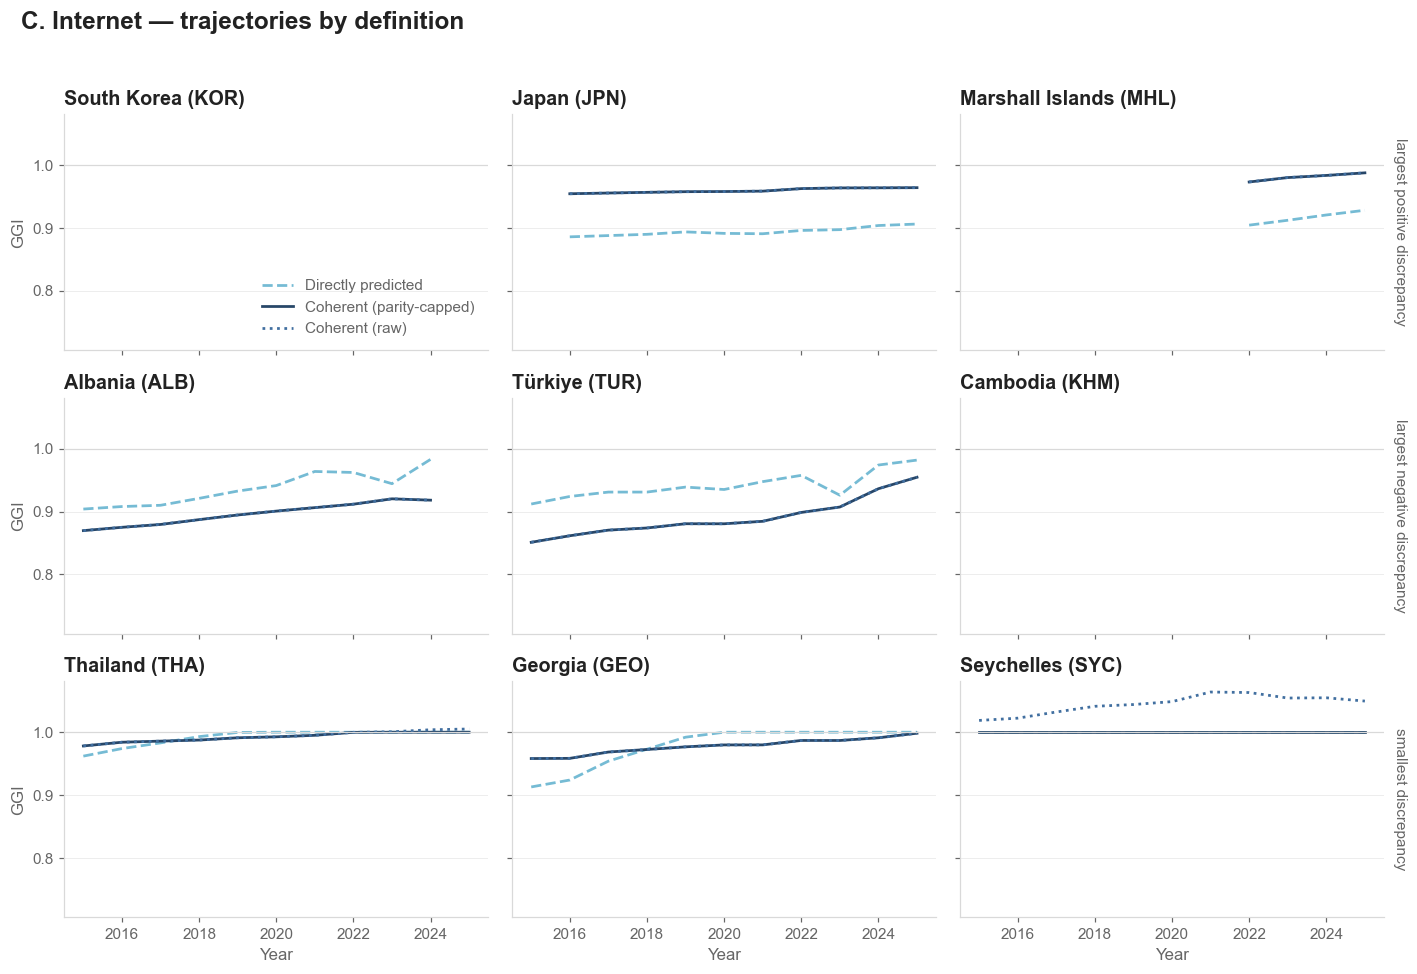

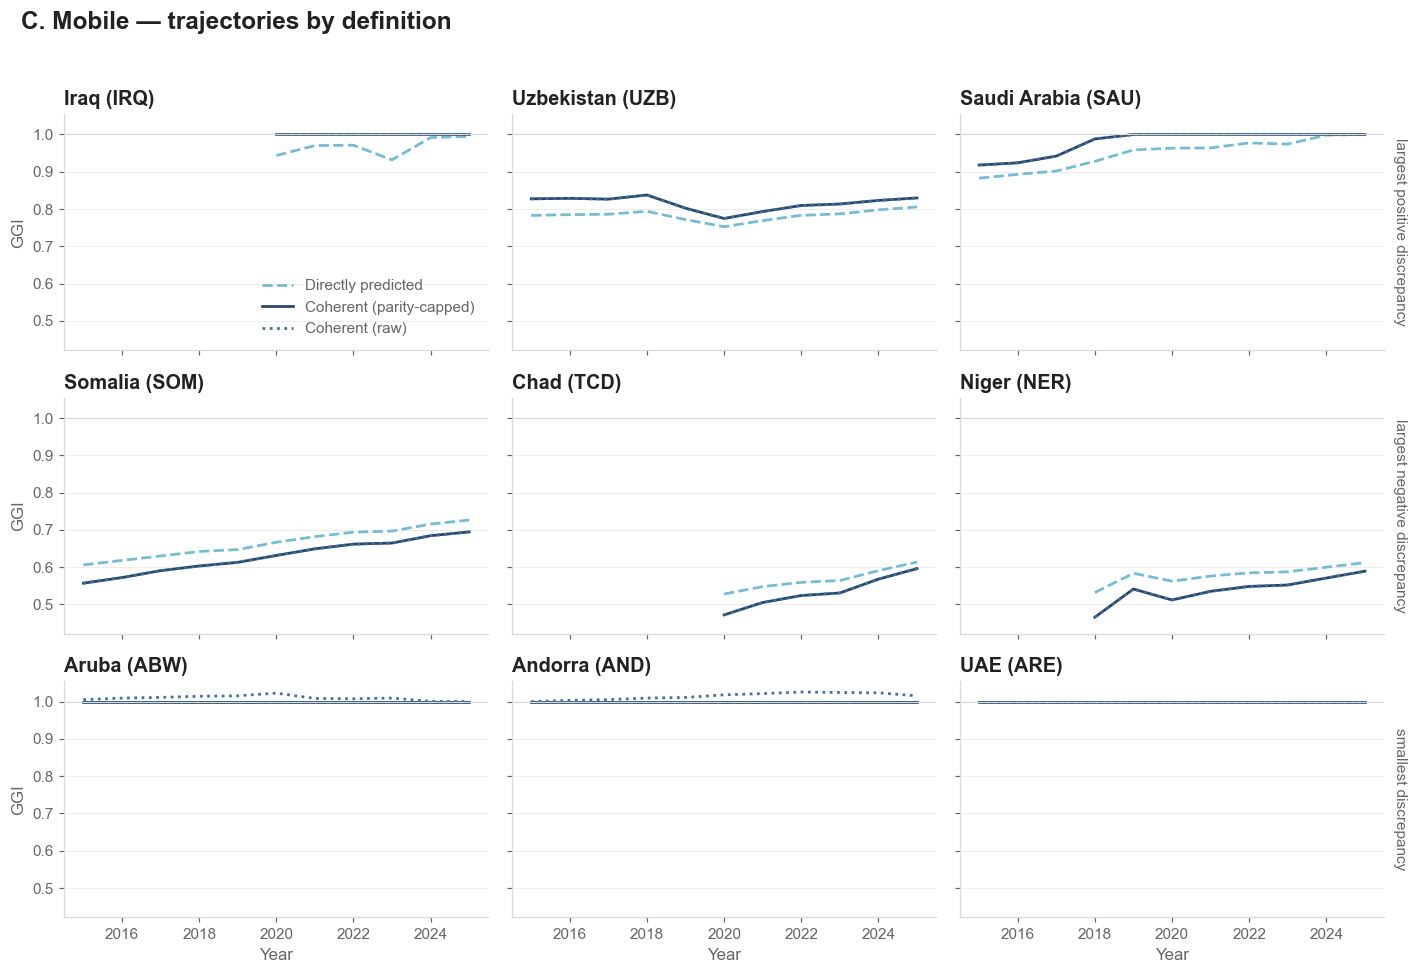

In [13]:
GROUP_TITLE = {'largest_positive': 'largest positive discrepancy',
               'largest_negative': 'largest negative discrepancy',
               'smallest': 'smallest discrepancy'}
LINE_STYLE = {'direct': dict(ls='--', color=PALETTE[2]),
              'coherent_parity': dict(ls='-', color=PALETTE[1]),
              'coherent_raw': dict(ls=':', color=PALETTE[4])}

for indicator in params.COHERENT_GGI['indicators']:
    picks = selection[selection['indicator'] == indicator]
    groups = ['largest_positive', 'largest_negative', 'smallest']
    n_per = picks.groupby('group').size().max()

    fig, axes = plt.subplots(len(groups), n_per, figsize=plot.figsize('tall'), sharex=True, sharey=True)
    for r, group in enumerate(groups):
        members = picks[picks['group'] == group].sort_values('mean_discrepancy', ascending=False)
        for c in range(n_per):
            ax = axes[r, c]
            if c >= len(members):
                ax.axis('off'); continue
            iso = members.iloc[c]['gid_0']
            block = trends[(trends['indicator'] == indicator) & (trends['gid_0'] == iso)]
            for definition, style in LINE_STYLE.items():
                sub = block[block['definition'] == definition].sort_values('year')
                ax.plot(sub['year'], sub['value'], linewidth=1.8, **style,
                        label=DEF_LABEL[definition] if (r == 0 and c == 0) else None)
            ax.axhline(1.0, color=GRID, linewidth=0.8)
            name = block['country'].iloc[0] if len(block) else iso
            tidy(ax, title=f'{name} ({iso})')
            if c == 0:
                ax.set_ylabel('GGI', fontsize=STYLE['tick_fs'], color=MUTED)
            if c == n_per - 1:
                # row tag on the right margin: the y axis is a GGI, not a discrepancy
                ax.text(1.02, 0.5, GROUP_TITLE[group], transform=ax.transAxes,
                        rotation=270, va='center', ha='left',
                        fontsize=STYLE['annot_fs'], color=MUTED)
            if r == len(groups) - 1:
                ax.set_xlabel('Year', fontsize=STYLE['tick_fs'], color=MUTED)

    axes[0, 0].legend(frameon=False, fontsize=STYLE['annot_fs'],
                      loc='lower right', labelcolor=MUTED)
    fig.suptitle(f'C. {indicator.capitalize()} — trajectories by definition',
                 fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
    fig.tight_layout(rect=[0, 0, 1, 0.96])
    plot.save_fig(fig, FIGDIR / f'D_country_trends_{indicator}.png')
    print(f'  C_country_trends_{indicator}.png')

## E. Regional robustness

The main regional trend figure, rebuilt under each of the three definitions on an **identical
country sample within each indicator** and an identical aggregation rule (unweighted country mean
within World Bank region). The only thing that varies between columns is the definition.

Sample: the filtered series (D43). Because a country-year is blanked under *all three* definitions
at once, the three columns still rest on exactly the same country-years — which is what makes this
a robustness check rather than three different samples. `n_countries` counts the countries actually
carrying a value in each region-year, so the internet panels rest on a smaller base than they did
before the filter; the mobile panels are essentially unchanged.


  D_regional_definitions_internet.png
  D_regional_definitions_mobile.png


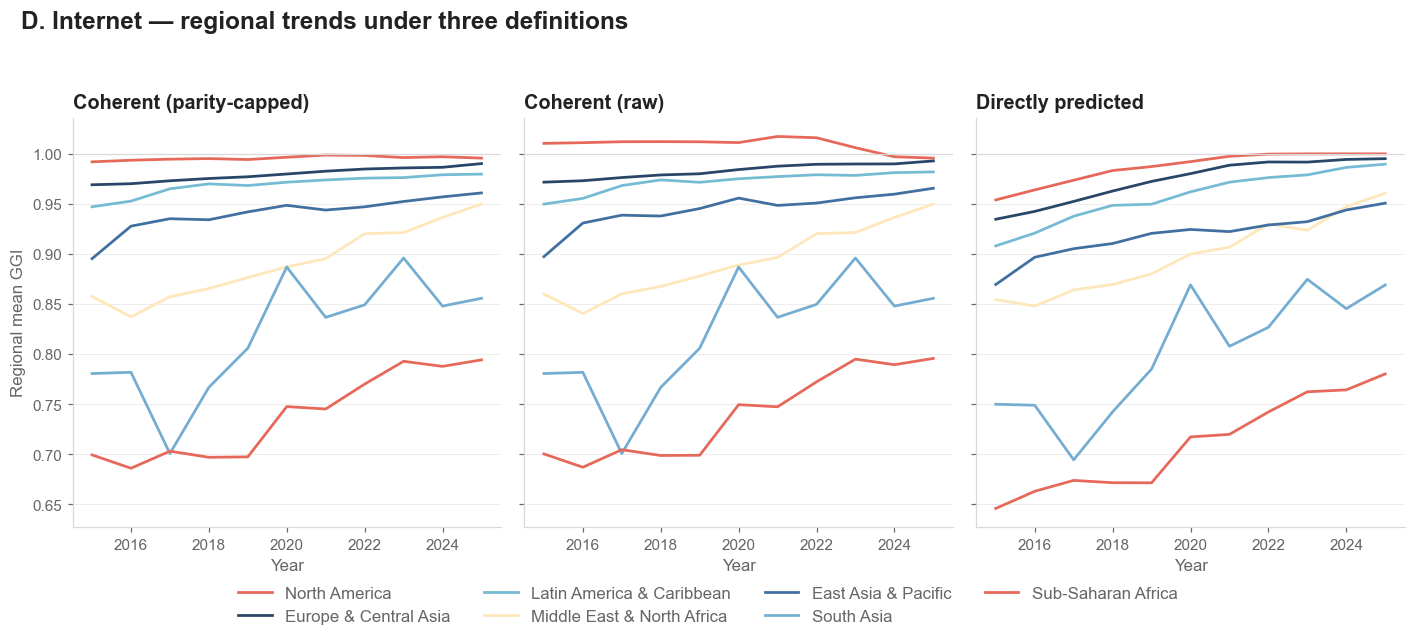

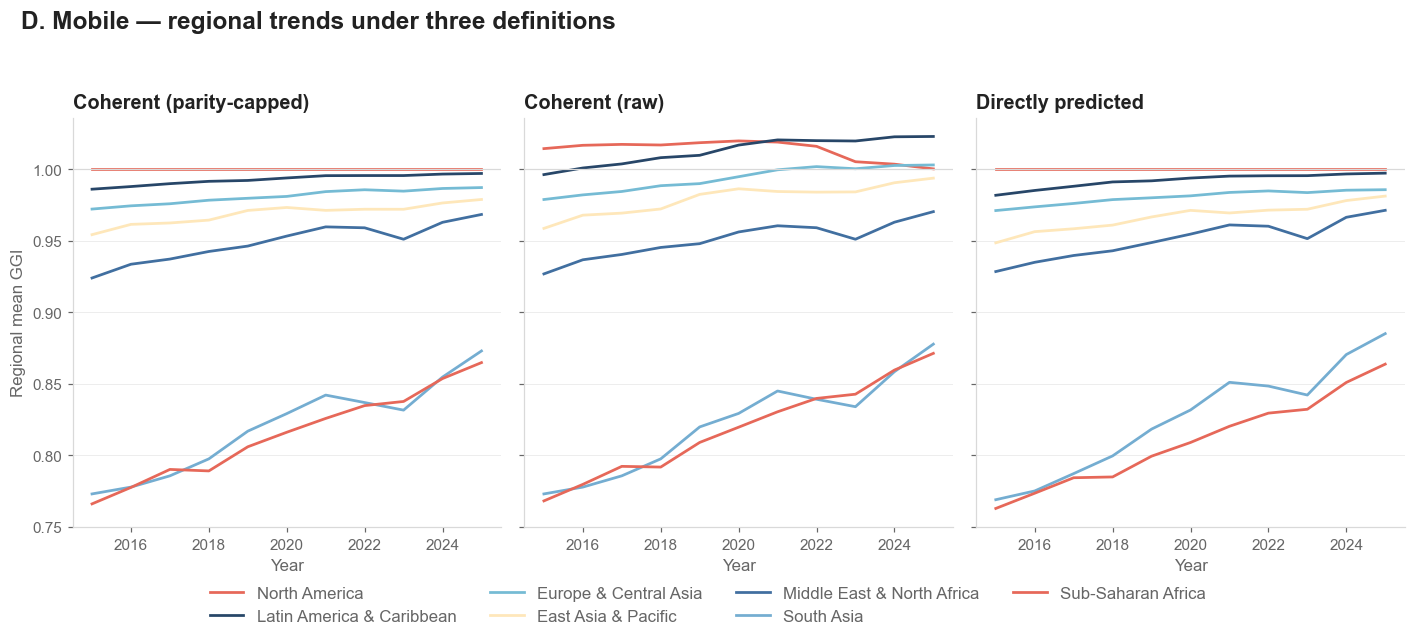

In [14]:
for indicator in params.COHERENT_GGI['indicators']:
    fig, axes = plt.subplots(1, 3, figsize=plot.figsize('wide'), sharey=True)
    block = regional[regional['indicator'] == indicator]
    order = (block[(block['definition'] == 'direct') & (block['year'] == 2025)]
             .sort_values('value', ascending=False)['region'].tolist())

    for ax, definition in zip(axes, ['coherent_parity', 'coherent_raw', 'direct']):
        sub = block[block['definition'] == definition]
        for i, region in enumerate(order):
            line = sub[sub['region'] == region].sort_values('year')
            ax.plot(line['year'], line['value'], linewidth=1.8,
                    color=PALETTE[i % len(PALETTE)])
        ax.axhline(1.0, color=GRID, linewidth=0.8)
        tidy(ax, title=DEF_LABEL[definition], xlabel='Year')
    axes[0].set_ylabel('Regional mean GGI', fontsize=STYLE['tick_fs'], color=MUTED)

    handles = [plt.Line2D([], [], color=PALETTE[i % len(PALETTE)], linewidth=1.8, label=r)
               for i, r in enumerate(order)]
    fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False,
               fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.06))

    fig.suptitle(f'D. {indicator.capitalize()} — regional trends under three definitions',
                 fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
    fig.tight_layout(rect=[0, 0.02, 1, 0.94])
    plot.save_fig(fig, FIGDIR / f'E_regional_definitions_{indicator}.png')
    print(f'  D_regional_definitions_{indicator}.png')

In [15]:
# regional values, change and rank under each definition
regional_table.round(4)

,indicator,definition,region,value_2015,value_2025,abs_change,rank_2025,rank_change
0,internet,coherent_parity,North America,0.9920,0.9957,0.0037,1,7
1,internet,coherent_parity,Europe & Central Asia,0.9691,0.9903,0.0211,2,6
2,internet,coherent_parity,Latin America & Caribbean,0.9471,0.9798,0.0326,3,5
3,internet,coherent_parity,East Asia & Pacific,0.8953,0.9610,0.0657,4,4
4,internet,coherent_parity,Middle East & North Africa,0.8577,0.9499,0.0922,5,2
5,internet,coherent_parity,South Asia,0.7806,0.8558,0.0751,6,3
6,internet,coherent_parity,Sub-Saharan Africa,0.6994,0.7943,0.0949,7,1
7,internet,coherent_raw,North America,1.0105,0.9957,-0.0147,1,7
8,internet,coherent_raw,Europe & Central Asia,0.9717,0.9929,0.0212,2,6
9,internet,coherent_raw,Latin America & Caribbean,0.9498,0.9820,0.0321,3,5


In [16]:
# where the definition changes the regional ordering
stability.round(4)

,indicator,region,rank_coherent_parity,rank_coherent_raw,rank_direct,value_coherent_parity,value_coherent_raw,value_direct,rank_changes,max_rank_shift,max_value_spread
0,internet,North America,1,1,1,0.9957,0.9957,1.0000,False,0,0.0043
1,internet,Europe & Central Asia,2,2,2,0.9903,0.9929,0.9952,False,0,0.0049
2,internet,Latin America & Caribbean,3,3,3,0.9798,0.9820,0.9897,False,0,0.0099
3,internet,Middle East & North Africa,5,5,4,0.9499,0.9499,0.9607,True,1,0.0108
4,internet,East Asia & Pacific,4,4,5,0.9610,0.9657,0.9507,True,1,0.0149
5,internet,South Asia,6,6,6,0.8558,0.8558,0.8691,False,0,0.0133
6,internet,Sub-Saharan Africa,7,7,7,0.7943,0.7958,0.7803,False,0,0.0155
7,mobile,North America,1,3,1,1.0000,1.0003,1.0000,True,2,0.0003
8,mobile,Latin America & Caribbean,2,1,2,0.9970,1.0229,0.9973,True,1,0.0259
9,mobile,Europe & Central Asia,3,2,3,0.9872,1.0030,0.9857,True,1,0.0173


## F. Appendix text

Generated from the tables above so the prose cannot drift from the numbers. It describes the two
definitions as alternative constructions rather than treating either as observed: both are model
output, and no survey measurement of the gender gap enters at this stage.

In [17]:
def appendix_paragraph():
    """compose the appendix text from the computed statistics"""
    lines = []

    r_lo = scatter_stats['pearson_r'].min()
    r_hi = scatter_stats['pearson_r'].max()
    lines.append(
        'We compare two constructions of the national digital gender gap. The first is the gender '
        'gap index predicted directly by its own model; the second is the internally coherent '
        'index, formed as the ratio of the separately predicted female and male adoption levels. '
        'Neither is an observed quantity: both are model output for country-months in which no '
        'survey was fielded, and the comparison below concerns their consistency with one another '
        'rather than their accuracy against a measured benchmark.')

    lines.append(
        f'Across 2015-2025 the two move together closely (Pearson r between {r_lo:.2f} and '
        f'{r_hi:.2f} in the snapshot years), but they are not interchangeable.')

    # Which sample each number below rests on. The distinction is easy to lose in generated prose
    # and the two halves of this appendix do not use the same one.
    kept = filter_report.set_index('indicator')['kept_pct']
    lines.append(
        f'Two samples are in play, and the text says which each figure comes from. The correlations '
        f'and difference distributions just quoted are computed on the full series, because they are '
        f'what motivates a threshold and must not be filtered by it. Everything from the '
        f'country-level and regional statements onward is computed after withholding country-years '
        f'in which the two indices differ by more than '
        f"{params.COHERENT_GGI['discrepancy_threshold']} - {100 - kept['internet']:.0f}% of internet "
        f"country-years and {100 - kept['mobile']:.0f}% of mobile ones - on the ground that where "
        f'the two constructions disagree sharply at least one of them is wrong about that '
        f'country-year and neither series says which. The withholding is applied to both indices '
        f'alike, so the comparison remains like-for-like.')

    for ind in params.COHERENT_GGI['indicators']:
        st = scatter_stats[scatter_stats['indicator'] == ind]
        first, last = st.iloc[0], st.iloc[-1]
        d = differences[differences['indicator'] == ind]['diff_parity']
        # the direction of travel differs by indicator, so do not hardcode "falls"
        delta = last['mean_abs_diff'] - first['mean_abs_diff']
        verb = ('falls from' if delta < -0.001 else
                'rises from' if delta > 0.001 else 'is essentially unchanged at')
        span = (f'{first["mean_abs_diff"]:.3f} in {int(first["year"])} to '
                f'{last["mean_abs_diff"]:.3f} in {int(last["year"])}'
                if abs(delta) > 0.001 else
                f'{first["mean_abs_diff"]:.3f} between {int(first["year"])} and {int(last["year"])}')
        lines.append(
            f'For {ind}, the mean absolute difference {verb} {span}, with a median signed '
            f'difference of {d.median():+.3f}; the coherent index exceeds parity for '
            f'{int(last["n_above_1_coherent_raw"])} countries in {int(last["year"])} before capping.')

    # A region only counts as "changed" if the primary measure (parity-capped) disagrees with the
    # direct index. A shift confined to the uncapped variant is reported separately, not conflated.
    swaps = []
    for ind in params.COHERENT_GGI['indicators']:
        s = stability[stability['indicator'] == ind]
        spread = s['max_value_spread'].max()
        primary = s[s['rank_direct'] != s['rank_coherent_parity']]
        raw_only = s[(s['rank_direct'] == s['rank_coherent_parity'])
                     & (s['rank_direct'] != s['rank_coherent_raw'])]

        if len(primary) == 0:
            note = (f'Regional orderings for {ind} are identical under the direct and the '
                    f'parity-capped coherent index, and regional means differ by at most '
                    f'{spread:.3f}, so the substantive regional picture is materially the same.')
            if len(raw_only):
                note += (f' Only the uncapped variant reorders, and only among regions already at '
                         f'parity ({", ".join(raw_only["region"])}).')
            lines.append(note)
        else:
            lines.append(
                f'Regional orderings for {ind} are stable in level terms - regional means differ by '
                f'at most {spread:.3f} across definitions - but the ranking is not invariant: '
                f'{", ".join(primary["region"])} change position.')
            for _, row in primary.iterrows():
                swaps.append(
                    f'{row["region"]} ({ind}: rank {int(row["rank_direct"])} under the direct index '
                    f'vs {int(row["rank_coherent_parity"])} under the coherent index)')

    if swaps:
        lines.append(
            'Conclusions that depend on regional ordering rather than level should therefore be '
            'stated with the definition made explicit. The affected cases are: ' + '; '.join(swaps) + '.')
    else:
        lines.append(
            'No regional conclusion in the paper changes sign or order between the two definitions.')

    picks = selection.sort_values('mean_discrepancy', ascending=False)
    worst = picks.iloc[0]
    best = picks.iloc[-1]
    lines.append(
        f'At country level the discrepancy is widest for {worst["country"]} '
        f'({worst["mean_discrepancy"]:+.3f} on {worst["indicator"]}) and '
        f'{best["country"]} ({best["mean_discrepancy"]:+.3f} on {best["indicator"]}); '
        'appendix figure C shows these trajectories under both definitions.')

    lines.append(
        'Two limitations bound this comparison. Both series are clipped to the unit interval '
        'upstream, so agreement near parity is partly mechanical rather than substantive; and the '
        'coherent index inherits the floor of the level models, taking the value zero where '
        'predicted female adoption is clipped to zero.')

    return '\n\n'.join(lines)


text = appendix_paragraph()
out = params.DOC / '05_coherent_ggi_comparison_report.md'
out.write_text('# Appendix: coherent vs directly predicted GGI\n\n'
               '<!-- generated by src/analysis_notebooks/05_coherent_ggi_comparison.ipynb — do not edit by hand -->\n\n'
               + text + '\n')
print(f'written to {out.relative_to(params.ROOT)}\n')
print(text)

written to doc/05_coherent_ggi_comparison_report.md

We compare two constructions of the national digital gender gap. The first is the gender gap index predicted directly by its own model; the second is the internally coherent index, formed as the ratio of the separately predicted female and male adoption levels. Neither is an observed quantity: both are model output for country-months in which no survey was fielded, and the comparison below concerns their consistency with one another rather than their accuracy against a measured benchmark.

Across 2015-2025 the two move together closely (Pearson r between 0.92 and 0.98 in the snapshot years), but they are not interchangeable.

Two samples are in play, and the text says which each figure comes from. The correlations and difference distributions just quoted are computed on the full series, because they are what motivates a threshold and must not be filtered by it. Everything from the country-level and regional statements onward is compu

## G. Validation against the survey ground truth

Every panel from here on uses the filtered series (D43), so the surveys shown are those whose
country-year survived the 0.07 discrepancy cut — 59 of 88 for internet, 88 of 89 for mobile. All
three definitions are filtered identically, so the comparison stays like-for-like. `gt_full` holds
the unfiltered table if the pre-filter picture is wanted.


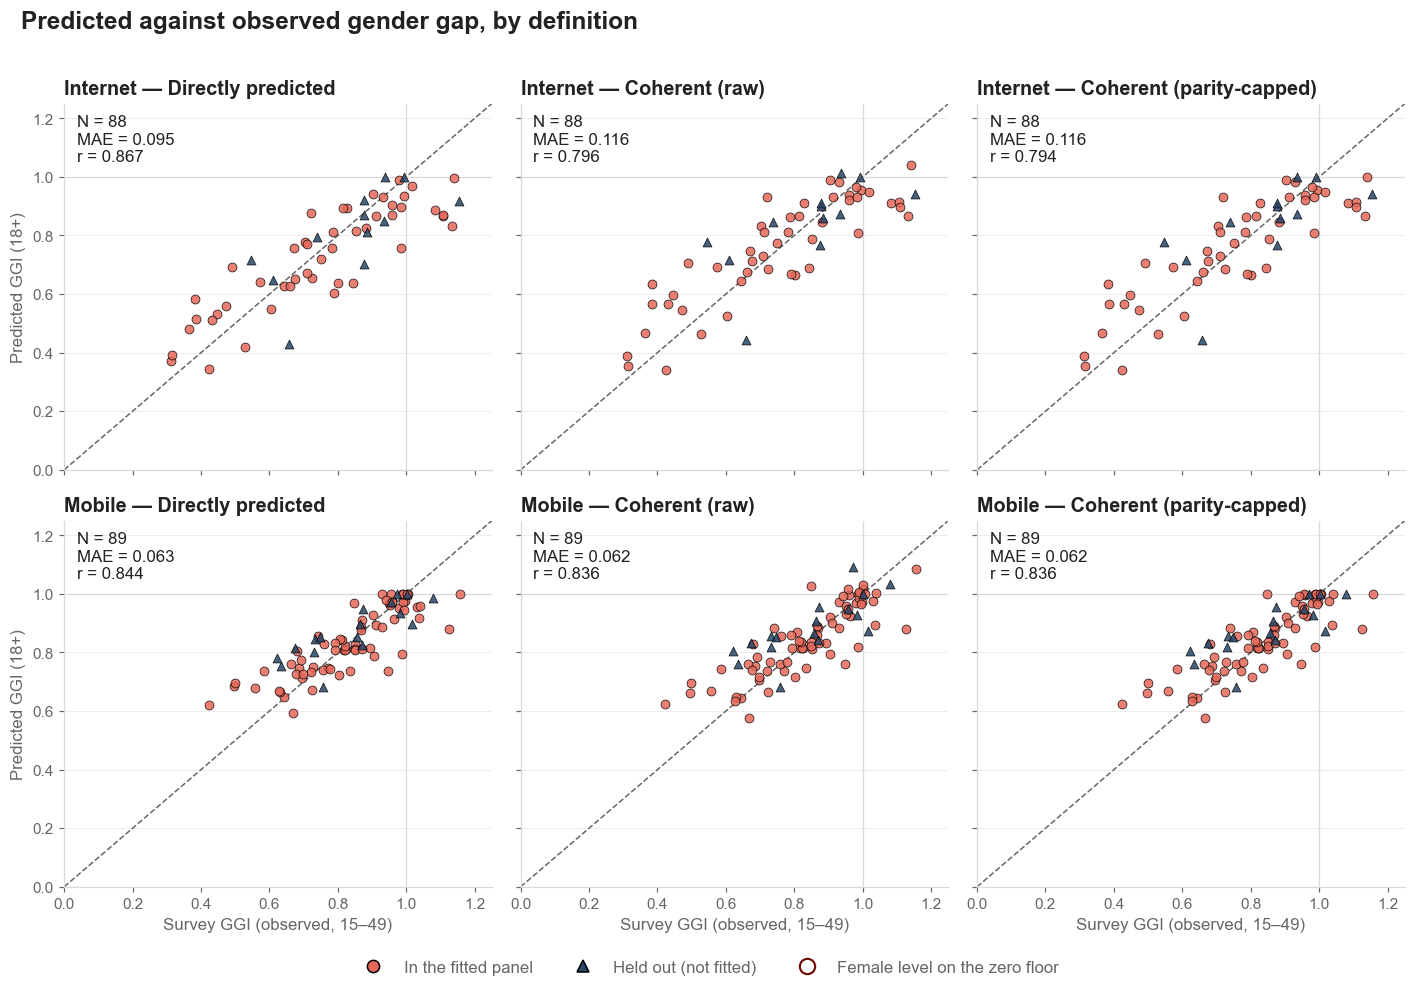

In [18]:
fig, axes = plt.subplots(2, 3, figsize=plot.figsize('tall'), sharex=True, sharey=True)

for row, indicator in enumerate(params.COHERENT_GGI['indicators']):
    for col, definition in enumerate(['direct', 'coherent_raw', 'coherent_parity']):
        ax = axes[row, col]
        block = gt[(gt['indicator'] == indicator) & (gt['definition'] == definition)]
        st = gt_stats[(gt_stats['indicator'] == indicator)
                      & (gt_stats['definition'] == definition)
                      & (gt_stats['sample'] == 'all')].iloc[0]

        lim = (0.0, 1.25)
        ax.plot(lim, lim, ls='--', color=MUTED, linewidth=1, zorder=1)
        ax.axhline(1.0, color=GRID, linewidth=0.8, zorder=1)
        ax.axvline(1.0, color=GRID, linewidth=0.8, zorder=1)

        # in-sample first so the held-out points, which carry the argument, sit on top
        for flag in (True, False):
            key = 'in_training' if flag else 'held_out'
            pts = block[block['in_training'] == flag]
            ax.scatter(pts['observed'], pts['predicted'], s=34, alpha=0.85,
                       marker=SAMPLE_MARKER[key], color=SAMPLE_COLOUR[key],
                       edgecolor=plot.EDGE, linewidth=0.5, zorder=3 if flag else 4)

        # Two points carry an explanation the axes cannot: ring them, so the reader is not left
        # to guess why a prediction is exactly zero. They are labelled below.
        floored = block[block['zero_floor'] & (definition != 'direct')]
        ax.scatter(floored['observed'], floored['predicted'], s=150, facecolors='none',
                   edgecolor=ZERO_RING, linewidth=1.4, zorder=5)

        ax.text(0.03, 0.97, f"N = {int(st['n'])}\nMAE = {st['mae']:.3f}\nr = {st['pearson_r']:.3f}",
                transform=ax.transAxes, va='top', ha='left',
                fontsize=STYLE['tick_fs'], color=INK)

        tidy(ax, title=f'{indicator.capitalize()} — {DEF_LABEL[definition]}')
        ax.set_xlim(lim); ax.set_ylim(lim)
        if row == 1:
            ax.set_xlabel('Survey GGI (observed, 15–49)', fontsize=STYLE['tick_fs'], color=MUTED)
        if col == 0:
            ax.set_ylabel('Predicted GGI (18+)', fontsize=STYLE['tick_fs'], color=MUTED)

        # Label the points sitting on the x-axis, offset right so they do not obscure the
        # scatter. The YEAR matters as much as the country: Mali appears twice in this panel
        # (2018 on the floor, 2023 at 0.44), and without it the two read as one contradictory
        # point. Coloured to match the ring.
        for _, row_ in block.iterrows():
            if row_['predicted'] < 0.01:
                ax.annotate(f"{row_['country']} {int(row_['year'])}",
                            (row_['observed'], row_['predicted']),
                            xytext=(13, 1), textcoords='offset points', va='bottom',
                            fontsize=STYLE['annot_fs'], color=ZERO_RING)



handles = [plt.Line2D([], [], marker=SAMPLE_MARKER[k], linestyle='None', markersize=8,
                      markerfacecolor=SAMPLE_COLOUR[k], markeredgecolor=plot.EDGE,
                      label=SAMPLE_LABEL[k])
           for k in ('in_training', 'held_out')]
handles.append(plt.Line2D([], [], marker='o', linestyle='None', markersize=10,
                          markerfacecolor='none', markeredgecolor=ZERO_RING, markeredgewidth=1.4,
                          label='Female level on the zero floor'))
fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.01))
fig.suptitle('Predicted against observed gender gap, by definition',
             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=(0, 0.03, 1, 0.97))
if STYLE['save']:
    plot.save_fig(fig, FIGDIR / 'G1_groundtruth_scatter.png')
plt.show()


### Accuracy, by definition and sample

Mean absolute error against the survey. Lower is better; the question is whether the coherent GGI,
which the project made primary in D16, tracks the observation at least as well as the direct
prediction it replaced.

The third series drops the rows where the predicted **female level sits exactly on the zero
floor** — there the coherent GGI is `0 / male = 0` by construction and reports the clip, not a gap
(D19). In this sample that is **Mali 2018 and Chad 2019**, internet only; no mobile row is
affected, which is why the mobile panel's three series coincide.

**That filter is not a fair-comparison device.** It is selected on the coherent measure's own
failure mode, which the direct prediction does not share, so "coherent beats direct once we drop
these" would be circular. It answers only: *how does the coherent GGI do where it is defined at
all* (D34).


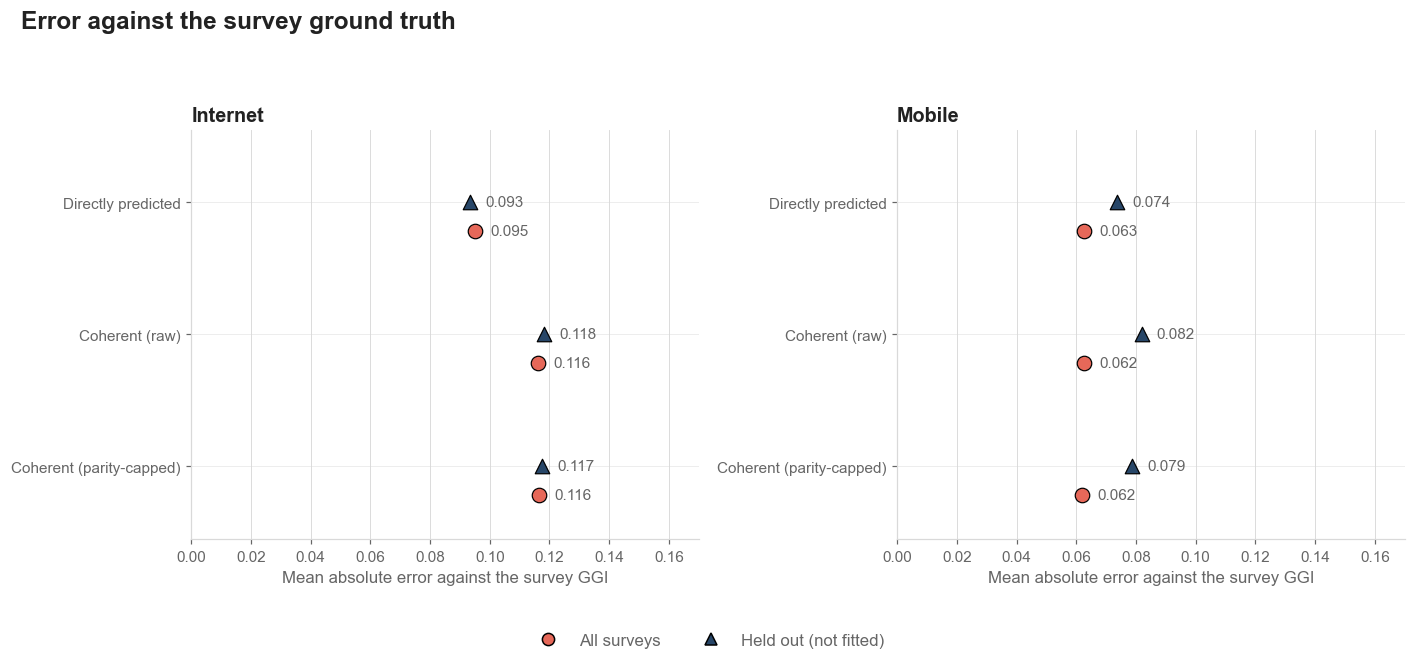

,indicator,definition,sample,n_dropped_zero_floor,n,bias,mae,rmse,r2,within_0.05,within_0.10,pearson_r,spearman_r
0,internet,coherent_parity,all,0,88,0.0210,0.1165,0.1498,0.5911,28.4091,52.2727,0.7938,0.8512
1,internet,coherent_parity,in_training,0,71,0.0153,0.1163,0.1511,0.6076,28.1690,53.5211,0.8036,0.8503
2,internet,coherent_parity,held_out,0,17,0.0446,0.1174,0.1439,0.3816,29.4118,47.0588,0.6659,0.8056
3,internet,coherent_parity,held_out_new_country,0,4,0.0529,0.0529,0.0641,0.8087,50.0000,75.0000,0.9886,0.9487
4,internet,coherent_raw,all,0,88,0.0216,0.1161,0.1494,0.5929,28.4091,53.4091,0.7956,0.8513
5,internet,coherent_raw,in_training,0,71,0.0159,0.1157,0.1507,0.6101,28.1690,54.9296,0.8057,0.8503
6,internet,coherent_raw,held_out,0,17,0.0454,0.1182,0.1442,0.3786,29.4118,47.0588,0.6656,0.8039
7,internet,coherent_raw,held_out_new_country,0,4,0.0560,0.0560,0.0674,0.7884,50.0000,75.0000,0.9818,0.8000
8,internet,direct,all,0,88,-0.0029,0.0951,0.1174,0.7489,29.5455,65.9091,0.8668,0.8661
9,internet,direct,in_training,0,71,-0.0004,0.0956,0.1179,0.7614,29.5775,64.7887,0.8748,0.8651


In [19]:
SAMPLES = ['all', 'held_out'] + (['all_excl_zero'] if ZERO_CTRL else [])
OFFSET = {'all': 0.22, 'held_out': 0.0, 'all_excl_zero': -0.22}

fig, axes = plt.subplots(1, 2, figsize=plot.figsize('wide'), sharex=True)

ORDER = ['direct', 'coherent_raw', 'coherent_parity']
for ax, indicator in zip(axes, params.COHERENT_GGI['indicators']):
    block = gt_stats[gt_stats['indicator'] == indicator]
    ypos = np.arange(len(ORDER))

    for key in SAMPLES:
        vals = [block[(block['definition'] == d) & (block['sample'] == key)]['mae'].squeeze()
                for d in ORDER]
        ax.scatter(vals, ypos + OFFSET[key], s=90, marker=SAMPLE_MARKER[key],
                   color=SAMPLE_COLOUR[key], edgecolor=plot.EDGE, linewidth=0.8, zorder=3)
        # Labels sit to the RIGHT of their own marker, not above it: the three samples differ by
        # ~0.003, so stacked labels land on the neighbouring series' marker.
        for v, y in zip(vals, ypos + OFFSET[key]):
            ax.annotate(f'{v:.3f}', (v, y), textcoords='offset points', xytext=(10, 0),
                        ha='left', va='center', fontsize=STYLE['annot_fs'], color=MUTED)

    ax.set_yticks(ypos)
    ax.set_yticklabels([DEF_LABEL[d] for d in ORDER])
    ax.set_ylim(len(ORDER) - 0.45, -0.55)
    ax.grid(axis='x', color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    tidy(ax, title=indicator.capitalize(),
         xlabel='Mean absolute error against the survey GGI')
    ax.set_xlim(0, max(0.17, block['mae'].max() * 1.5))

handles2 = [plt.Line2D([], [], marker=SAMPLE_MARKER[k], linestyle='None', markersize=8,
                       markerfacecolor=SAMPLE_COLOUR[k], markeredgecolor=plot.EDGE,
                       label=SAMPLE_LABEL[k])
            for k in SAMPLES]
fig.legend(handles=handles2, loc='lower center', ncol=len(SAMPLES), frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.10))
fig.suptitle('Error against the survey ground truth', fontsize=STYLE['title_fs'],
             color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=(0, 0, 1, 0.92))
if STYLE['save']:
    plot.save_fig(fig, FIGDIR / 'G2_groundtruth_mae.png')
plt.show()

gt_stats.round(4)


### Where the error comes from

The GGI is a ratio of two predicted levels, so any error in it is inherited. Scoring the levels
separately says whether the women's series, the men's series, or the ratio construction is
responsible.


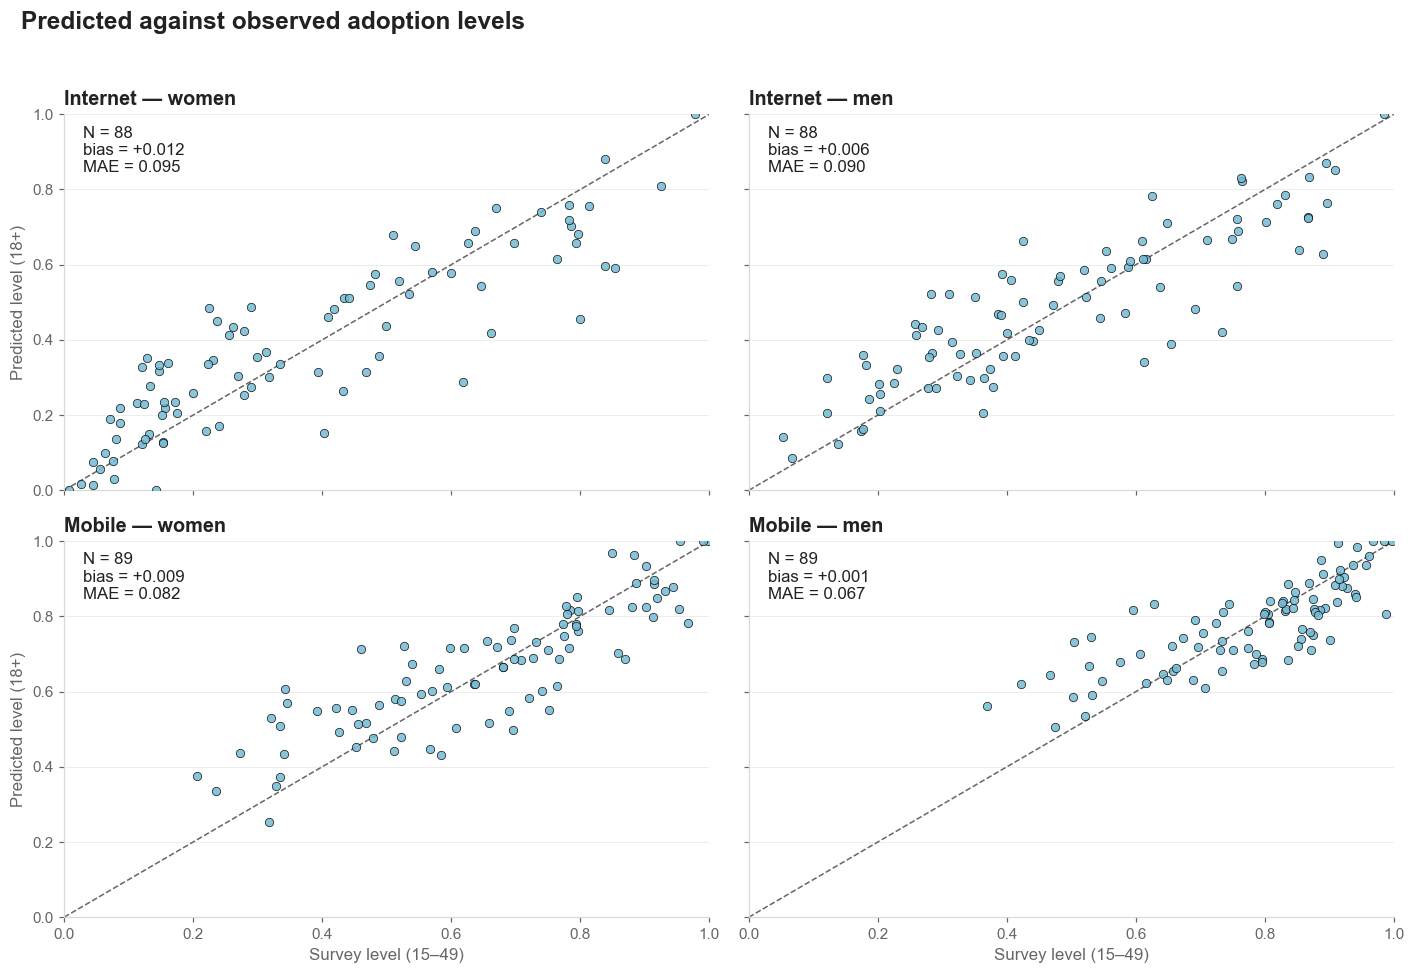

,indicator,sex,sample,n,bias,mae,rmse,r2,within_0.05,within_0.10,pearson_r,spearman_r
0,internet,men,all,88,0.0060,0.0903,0.1166,0.7561,34.0909,69.3182,0.8705,0.8615
1,internet,men,in_training,71,0.0033,0.0838,0.1104,0.7758,36.6197,74.6479,0.8822,0.8801
2,internet,men,held_out,17,0.0172,0.1172,0.1396,0.6317,23.5294,47.0588,0.7983,0.7034
3,internet,men,held_out_new_country,4,0.0108,0.0229,0.0240,0.9914,100.0000,100.0000,0.9979,1.0000
4,internet,women,all,88,0.0115,0.0949,0.1232,0.7810,34.0909,60.2273,0.8850,0.8844
5,internet,women,in_training,71,0.0082,0.0840,0.1098,0.8167,36.6197,64.7887,0.9051,0.9028
6,internet,women,held_out,17,0.0256,0.1404,0.1680,0.6144,23.5294,41.1765,0.7899,0.7892
7,internet,women,held_out_new_country,4,0.0406,0.0406,0.0426,0.9799,75.0000,100.0000,0.9997,1.0000
8,mobile,men,all,89,0.0011,0.0668,0.0894,0.6278,44.9438,77.5281,0.7928,0.8083
9,mobile,men,in_training,72,-0.0013,0.0684,0.0905,0.6347,43.0556,79.1667,0.7973,0.8095


In [20]:
fig, axes = plt.subplots(2, 2, figsize=plot.figsize('tall'), sharex=True, sharey=True)

for row, indicator in enumerate(params.COHERENT_GGI['indicators']):
    for col, sex in enumerate(['women', 'men']):
        ax = axes[row, col]
        block = gt_levels[(gt_levels['indicator'] == indicator) & (gt_levels['sex'] == sex)]
        st = gt_level_stats[(gt_level_stats['indicator'] == indicator)
                            & (gt_level_stats['sex'] == sex)].iloc[0]

        lim = (0.0, 1.0)
        ax.plot(lim, lim, ls='--', color=MUTED, linewidth=1, zorder=1)
        ax.scatter(block['observed'], block['predicted'], s=30, alpha=0.85,
                   color=PALETTE[2], edgecolor=plot.EDGE, linewidth=0.5, zorder=3)

        ax.text(0.03, 0.97,
                f"N = {int(st['n'])}\nbias = {st['bias']:+.3f}\nMAE = {st['mae']:.3f}",
                transform=ax.transAxes, va='top', ha='left',
                fontsize=STYLE['tick_fs'], color=INK)

        tidy(ax, title=f"{indicator.capitalize()} — {sex}")
        ax.set_xlim(lim); ax.set_ylim(lim)
        if row == 1:
            ax.set_xlabel('Survey level (15–49)', fontsize=STYLE['tick_fs'], color=MUTED)
        if col == 0:
            ax.set_ylabel('Predicted level (18+)', fontsize=STYLE['tick_fs'], color=MUTED)

fig.suptitle('Predicted against observed adoption levels', fontsize=STYLE['title_fs'],
             color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=(0, 0, 1, 0.96))
if STYLE['save']:
    plot.save_fig(fig, FIGDIR / 'G3_groundtruth_levels.png')
plt.show()

gt_level_stats.round(4)


In [21]:
# the surveys the models never saw, worst-fitting first — the rows worth reading individually.
# Note both zero-floor rows are *in* the fitted panel, so none of them appear here; that is why
# the held-out numbers are identical with and without the filter.
held = gt[(~gt['in_training']) & (gt['definition'] == 'coherent_parity')]
display((held[['indicator', 'gid_0', 'country', 'year', 'survey_type',
               'observed', 'predicted', 'error']]
         .assign(abs_error=lambda d: d['error'].abs())
         .sort_values(['indicator', 'abs_error'], ascending=[True, False])
         .drop(columns='abs_error').round(4).reset_index(drop=True)))

# every row the zero-floor filter removes, under each definition
gt[gt['zero_floor']][['indicator', 'definition', 'gid_0', 'country', 'year', 'survey_type',
                      'in_training', 'observed', 'predicted']].round(4).reset_index(drop=True)


,indicator,gid_0,country,year,survey_type,observed,predicted,error
0,internet,NGA,Nigeria,2024,dhs8,0.5453,0.7791,0.2338
1,internet,MLI,Mali,2023,dhs8,0.6582,0.4440,-0.2142
2,internet,LSO,Lesotho,2022,dhs8,1.1540,0.9412,-0.2128
3,internet,ZMB,Zambia,2024,dhs8,0.7380,0.8446,0.1067
4,internet,SEN,Senegal,2023,continuous dhs8,0.8756,0.7692,-0.1064
5,internet,MOZ,Mozambique,2022,dhs8,0.6099,0.7157,0.1058
6,internet,NRU,Nauru,2023,mics6,0.9366,1.0000,0.0634
7,internet,LAO,Laos,2023,mics6,0.9342,0.8736,-0.0606
8,internet,VUT,Vanuatu,2023,mics6,0.8775,0.9116,0.0342
9,internet,JOR,Jordan,2023,dhs8,0.8846,0.8601,-0.0245


,indicator,definition,gid_0,country,year,survey_type,in_training,observed,predicted


## H. The three definitions on the surveys the models never saw

Section F scores all 88–89 country-years, most of which are *in* the fitted panel. This section
keeps only the **17 surveys added in the 2026-08 refresh**, which no model saw. It is the same
question as F — which definition tracks the observation — asked where the answer cannot be fit.

The outcomes behind these ratios, country by country, are in
`08_01_unseen_survey_validation.ipynb`; here the subject is only the choice between definitions.

Both caveats from F still apply: surveys are 15–49 against 18+ predictions, and n = 17 is small
enough that a difference of a few thousandths means nothing.

In [22]:
held = gt[~gt['in_training']].copy()
print(f"{held['gid_0'].nunique()} countries | {len(held)//len(DEF_LABEL)} surveys per indicator")

# head to head: for each survey, which definition landed closest
wide = held.pivot_table(index=['indicator', 'gid_0', 'country', 'year', 'survey_type', 'observed'],
                        columns='definition', values='error').reset_index()
for d in DEF_LABEL:
    wide[f'abs_{d}'] = wide[d].abs()
wide['closest'] = wide[[f'abs_{d}' for d in DEF_LABEL]].idxmin(axis=1).str.removeprefix('abs_')

wins = (wide.groupby(['indicator', 'closest']).size()
        .unstack(fill_value=0).reindex(columns=list(DEF_LABEL), fill_value=0))
print('\nsurveys where each definition came closest:')
display(wins)

gt_stats[gt_stats['sample'] == 'held_out'].round(4)

17 countries | 29 surveys per indicator

surveys where each definition came closest:


closest,coherent_parity,coherent_raw,direct
indicator,,,
internet,8,0,4
mobile,5,1,11


,indicator,definition,sample,n_dropped_zero_floor,n,bias,mae,rmse,r2,within_0.05,within_0.10,pearson_r,spearman_r
2,internet,coherent_parity,held_out,0,17,0.0446,0.1174,0.1439,0.3816,29.4118,47.0588,0.6659,0.8056
6,internet,coherent_raw,held_out,0,17,0.0454,0.1182,0.1442,0.3786,29.4118,47.0588,0.6656,0.8039
10,internet,direct,held_out,0,17,-0.0135,0.0933,0.1153,0.6025,29.4118,70.5882,0.7825,0.7885
14,mobile,coherent_parity,held_out,0,17,0.0330,0.0786,0.0954,0.5208,35.2941,64.7059,0.7762,0.8329
18,mobile,coherent_raw,held_out,0,17,0.0404,0.0819,0.0982,0.4926,35.2941,58.8235,0.7622,0.8260
22,mobile,direct,held_out,0,17,0.0282,0.0736,0.0871,0.6006,41.1765,64.7059,0.8187,0.8331


### Is the coherent GGI closer or further than the direct prediction, survey by survey?

Each line runs from the absolute error under the direct prediction to the error under the coherent
(parity-capped) GGI. A line sloping **down to the right** means the coherent definition was closer
on that survey. Aggregates hide that this is a mix, not a uniform shift.

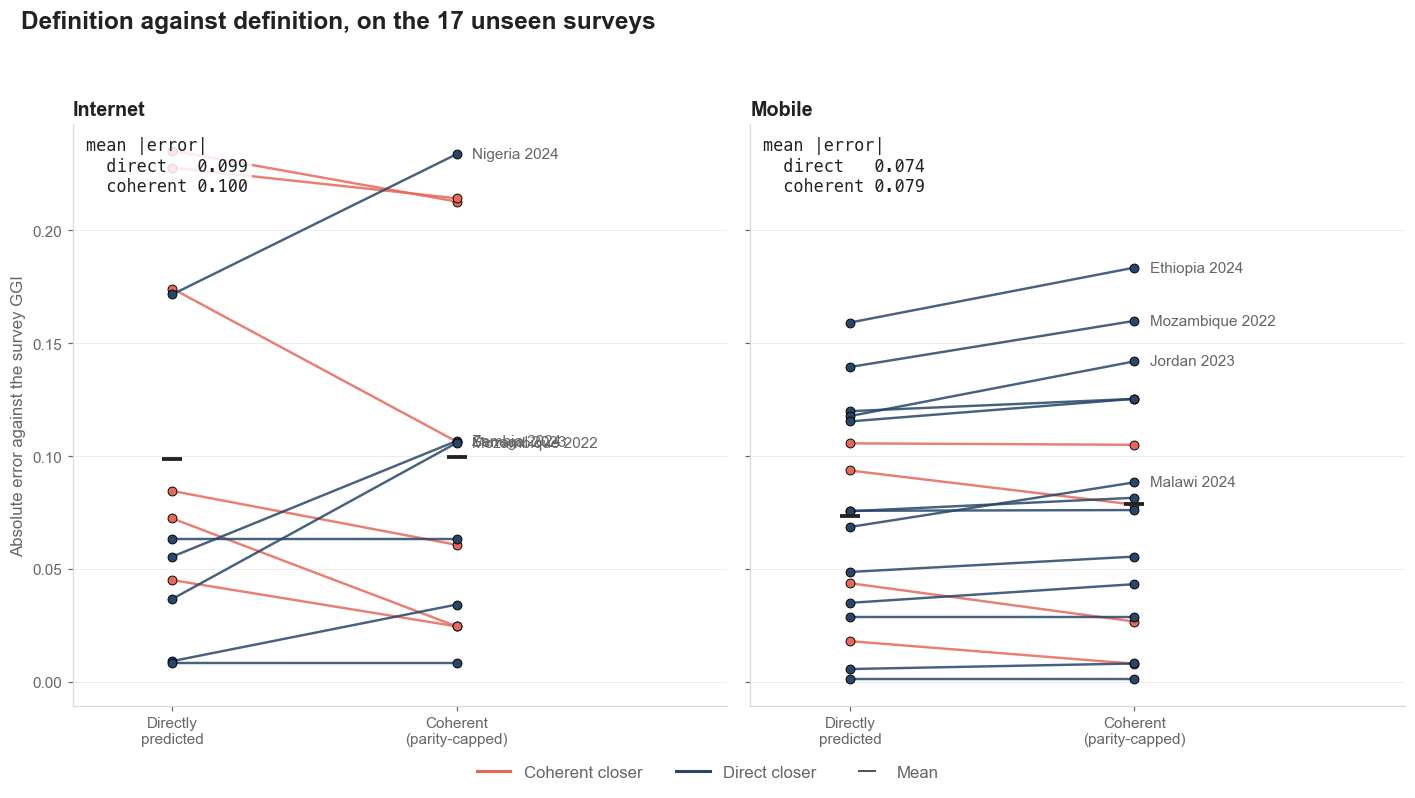

In [23]:
fig, axes = plt.subplots(1, 2, figsize=plot.figsize('full'), sharey=True)

N_LABEL = 4          # only the biggest movers get named; 17 labels is unreadable
LABEL_GAP = 0.012    # minimum vertical spacing between labels, in data units

for ax, indicator in zip(axes, params.COHERENT_GGI['indicators']):
    block = (wide[wide['indicator'] == indicator]
             .assign(shift=lambda d: (d['abs_coherent_parity'] - d['abs_direct']).abs())
             .sort_values('abs_direct', ascending=False).reset_index(drop=True))

    for _, r in block.iterrows():
        better = r['abs_coherent_parity'] < r['abs_direct']
        colour = PALETTE[0] if better else PALETTE[1]
        ax.plot([0, 1], [r['abs_direct'], r['abs_coherent_parity']],
                color=colour, linewidth=1.6, alpha=0.85, zorder=2)
        ax.scatter([0, 1], [r['abs_direct'], r['abs_coherent_parity']], s=34,
                   color=colour, edgecolor=plot.EDGE, linewidth=0.6, zorder=3)

    # Labels are placed at their own y, then pushed apart just enough not to overlap: several
    # surveys land within a thousandth of each other and would otherwise print on top.
    named = block.nlargest(N_LABEL, 'shift').sort_values('abs_coherent_parity')
    last_y = -np.inf
    for _, r in named.iterrows():
        y = max(r['abs_coherent_parity'], last_y + LABEL_GAP)
        ax.annotate(f"{r['country']} {int(r['year'])}", (1, r['abs_coherent_parity']),
                    xytext=(10, 0), textcoords='offset points', va='center',
                    xycoords='data', annotation_clip=False,
                    fontsize=STYLE['annot_fs'], color=MUTED)
        last_y = y

    means = {k: block[k].mean() for k in ('abs_direct', 'abs_coherent_parity')}
    for x, key in ((0, 'abs_direct'), (1, 'abs_coherent_parity')):
        ax.scatter([x], [means[key]], s=170, marker='_', color=INK, linewidth=2.5, zorder=4)

    # the two means as one corner note, so they never land in the label column
    ax.text(0.02, 0.98,
            f"mean |error|\n  direct   {means['abs_direct']:.3f}\n"
            f"  coherent {means['abs_coherent_parity']:.3f}",
            transform=ax.transAxes, va='top', ha='left', family='monospace',
            fontsize=STYLE['tick_fs'], color=INK,
            bbox=dict(facecolor='white', edgecolor='none', alpha=0.85, pad=3))

    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Directly\npredicted', 'Coherent\n(parity-capped)'])
    ax.set_xlim(-0.35, 1.95)
    ax.grid(axis='y', color=GRID, linewidth=0.6)
    ax.set_axisbelow(True)
    tidy(ax, title=indicator.capitalize())

axes[0].set_ylabel('Absolute error against the survey GGI',
                   fontsize=STYLE['tick_fs'], color=MUTED)
handles = [plt.Line2D([], [], color=PALETTE[0], linewidth=2, label='Coherent closer'),
           plt.Line2D([], [], color=PALETTE[1], linewidth=2, label='Direct closer'),
           plt.Line2D([], [], color=INK, linewidth=2.5, marker='_', linestyle='None',
                      markersize=12, label='Mean')]
fig.legend(handles=handles, loc='lower center', ncol=3, frameon=False,
           fontsize=STYLE['tick_fs'], labelcolor=MUTED, bbox_to_anchor=(0.5, -0.04))
fig.suptitle('Definition against definition, on the 17 unseen surveys',
             fontsize=STYLE['title_fs'], color=INK, fontweight='bold', x=0.02, ha='left')
fig.tight_layout(rect=(0, 0, 1, 0.94))
if STYLE['save']:
    plot.save_fig(fig, FIGDIR / 'H_unseen_definition_duel.png')
plt.show()


### Survey by survey

Signed error under each definition; positive means the model sits above the survey.

In [24]:
(wide[['indicator', 'gid_0', 'country', 'year', 'survey_type', 'observed']
      + list(DEF_LABEL) + ['closest']]
 .sort_values(['indicator', 'year', 'gid_0'])
 .round(4).reset_index(drop=True))

definition,indicator,gid_0,country,year,survey_type,observed,coherent_parity,coherent_raw,direct,closest
0,internet,LSO,Lesotho,2022,dhs8,1.1540,-0.2128,-0.2128,-0.2353,coherent_parity
1,internet,MOZ,Mozambique,2022,dhs8,0.6099,0.1058,0.1058,0.0366,direct
2,internet,JOR,Jordan,2023,dhs8,0.8846,-0.0245,-0.0245,-0.0723,coherent_parity
3,internet,LAO,Laos,2023,mics6,0.9342,-0.0606,-0.0606,-0.0845,coherent_parity
4,internet,MLI,Mali,2023,dhs8,0.6582,-0.2142,-0.2142,-0.2278,coherent_parity
5,internet,NRU,Nauru,2023,mics6,0.9366,0.0634,0.0759,0.0634,coherent_parity
6,internet,QAT,Qatar,2023,mics6,0.9919,0.0081,0.0081,0.0081,coherent_parity
7,internet,SEN,Senegal,2023,continuous dhs8,0.8756,-0.1064,-0.1064,-0.1742,coherent_parity
8,internet,TUN,Tunisia,2023,mics6,0.8771,0.0245,0.0245,0.0450,coherent_parity
9,internet,VUT,Vanuatu,2023,mics6,0.8775,0.0342,0.0342,-0.0091,direct


## Notes

- Figures write to `outputs/fig/05_coherent_ggi_comparison/`; the figure-ready CSVs live in
  `outputs/tables/05_coherent_ggi_comparison/` under the `ggi_comparison_` prefix, one per panel.
- **Sections A–C use the full series; sections D onward use the filtered one.** The 0.07 discrepancy
  threshold (D43) is what separates them, and it is chosen inside section C — so the sections that
  motivate the cut are not themselves subject to it.
- The filter blanks a country-year under *all three* definitions for that indicator, so the
  definition comparisons stay like-for-like. Indicators filter independently: a country-year can
  survive for mobile and not for internet.
- `annual_all` and `gt_full` hold the unfiltered frames throughout, if the pre-filter picture is
  wanted for a specific check.
- The common sample (`common_sample`) drops any country not complete under all three definitions and
  **both** indicators. After the filter that is a much harsher rule — 120 of 211 countries survive
  it — so sections D and E work off the per-indicator sample instead, which is what the threshold
  actually defines. The common sample is printed in section C for contrast only.
- Panel A plots the **raw** coherent GGI so values above parity remain visible. Panels B and D use
  the parity-capped variant, which is the primary measure (D16); panel D shows the raw variant
  alongside it for comparison.


## Write this notebook's tables

Date-stamped into `outputs/tables/05_coherent_ggi_comparison/`, so a
rerun never replaces the vintage an earlier figure was built on.


In [25]:
from datetime import datetime

stamp = f'{datetime.now():%Y%m%d}'
for name, frame in [('scatter', scatter), ('scatter_stats', scatter_stats),
                    ('differences', differences), ('difference_summary', diff_summary),
                    ('trend_selection', selection), ('trends', trends),
                    ('regional', regional), ('regional_table', regional_table),
                    ('rank_stability', stability)]:
    path = params.table_dir(NOTEBOOK) / f'ggi_comparison_{name}_{stamp}.csv'
    frame.to_csv(path, index=False)
    print(f'{path.name:52s} {len(frame):5d} rows')


ggi_comparison_scatter_20260831.csv                   1260 rows
ggi_comparison_scatter_stats_20260831.csv                6 rows
ggi_comparison_differences_20260831.csv               4620 rows
ggi_comparison_difference_summary_20260831.csv          12 rows
ggi_comparison_trend_selection_20260831.csv             18 rows
ggi_comparison_trends_20260831.csv                     594 rows
ggi_comparison_regional_20260831.csv                   462 rows
ggi_comparison_regional_table_20260831.csv              42 rows
ggi_comparison_rank_stability_20260831.csv              14 rows
